# 6. pan_atlas — curated multi-atlas analysis

This notebook merges the useful parts of **4. pan_atlas** and **4.1 atlas_group** into one non-redundant workflow. It uses the organizational and grid conventions of the curated HPA notebook, but it does **not** reproduce the HPA cascade analysis.

The analysis is restricted to **Pearson** and **MSE**. It:

1. downloads or reuses HPA, HPA subcellular, UniProtKB, GOA, Reactome and WikiPathways resources;
2. normalizes all memberships into one atlas table;
3. constructs metric-specific evaluated universes and threshold sets;
4. reports each atlas group's size in the loaded resource, the overall tested universe and the current metric universe;
5. computes capture, expected overlap, fold enrichment, Fisher exact tests and FDR for every retained group, including zero-overlap groups;
6. creates compact grids that separate universe coverage, enrichment and capture without repeating the same top-group view in multiple formats.

All percentages state their denominator explicitly. The loaded atlas denominators are derived from the downloaded files and are not treated as immutable reference counts.


## 1. Analysis conventions

**Metric universes.** Pearson and MSE may be available for different genes. Each threshold is therefore tested against the genes with a valid value for that metric. Direct Pearson–MSE comparisons use only the joint evaluated universe.

**Group denominators.** Each atlas group has three useful sizes:

- `n_genes_atlas_loaded`: unique genes in the loaded atlas resource;
- `n_genes_tested_any_metric`: genes with at least one valid Pearson or MSE value;
- `n_genes_in_metric_universe`: genes with a valid value for the threshold's metric.

**Statistical denominator.** Fisher enrichment and expected overlap use `n_genes_in_metric_universe`, because this is the population from which a metric-specific threshold set can be selected.

**Capture denominators.** The notebook reports capture against the metric universe, the tested-any universe and the full loaded atlas group. These answer different questions and should not be substituted for one another.


In [1]:
from pathlib import Path
from collections import OrderedDict
import datetime as dt
import gzip
import math
import re
import shutil
import textwrap
import urllib.parse
import urllib.request
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    from scipy.stats import fisher_exact, hypergeom
except Exception as exc:
    fisher_exact = None
    hypergeom = None
    warnings.warn(f'SciPy is unavailable; inferential fields will be NaN. {exc}')

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 260)
pd.set_option('display.max_colwidth', 140)

BASE_DIR = Path.cwd()
DOWNLOAD_DIR = BASE_DIR / 'pan_atlas_downloads'
OUTPUT_DIR = BASE_DIR / '6_pan_atlas_outputs'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
RESOURCE_ZIP = BASE_DIR / 'pan_atlas_resources.zip'
for folder in (DOWNLOAD_DIR, OUTPUT_DIR, TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Resource behaviour
RUN_DOWNLOADS = True
OVERWRITE_DOWNLOADS = False

# Performance input. Add explicit paths here when automatic discovery is not desired.
PERFORMANCE_TABLE_PATHS = []
AUTO_DISCOVER_PERFORMANCE_TABLE = True
MODEL_FAMILY_FILTER = None
COLUMN_OVERRIDES = {'gene': None, 'protein': None, 'method': None, 'pearson': None, 'mse': None}

# Pearson and MSE only. Add or remove threshold values here.
SELECTED_THRESHOLDS_BY_METRIC = OrderedDict([
    ('Pearson', [0.50, 0.70]),
    ('MSE', [0.20, 0.30]),
])
METRIC_ORDER = {'Pearson': 0, 'MSE': 1}

# Keep a permissive full export, but use more stable groups in main figures.
MIN_GROUP_SIZE_EXPORT = 5
MIN_GROUP_SIZE_PLOTS = 10
MIN_OVERLAP_FOR_FLAG = 3
FDR_CUTOFF = 0.05
FOLD_ENRICHMENT_CUTOFF = 1.50
TOP_N_RANKED = 14
TOP_N_CAPTURE_PER_SOURCE = 14

# Figure behaviour
COMPACT_GRID_MAX_COLS = 2
SAVE_PNG = True
SAVE_SVG = False
SAVE_PDF = False
DISPLAY_MAIN_FIGURES = True
MAKE_QC_FIGURES = True
DPI = 180

mpl.rcParams.update({
    'figure.dpi': 125,
    'savefig.dpi': DPI,
    'font.size': 9.0,
    'axes.titlesize': 10.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 9.2,
    'xtick.labelsize': 7.8,
    'ytick.labelsize': 7.8,
    'legend.fontsize': 8.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

print('Base directory:', BASE_DIR.resolve())
print('Output directory:', OUTPUT_DIR.resolve())
print('Thresholds:', dict(SELECTED_THRESHOLDS_BY_METRIC))


Base directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Output directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\6_pan_atlas_outputs
Thresholds: {'Pearson': [0.5, 0.7], 'MSE': [0.2, 0.3]}


In [2]:
def safe_filename(text, max_len=180):
    text = re.sub(r'[^A-Za-z0-9._ -]+', '_', str(text))
    text = re.sub(r'\s+', '_', text).strip('._-')
    return (text[:max_len] or 'figure')


def wrap_label(text, width=42):
    return '\n'.join(textwrap.wrap(str(text), width=width, break_long_words=False))


def normalize_text(value):
    value = str(value).strip().replace('–', '-').replace('—', '-').replace('−', '-')
    return re.sub(r'\s+', ' ', value).casefold()


def clean_gene_symbol(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if not value or value.casefold() in {'nan', 'none', 'na', 'null'}:
        return np.nan
    value = re.split(r'[;|,]+', value)[0].strip()
    value = re.sub(r'\.\d+$', '', value)
    value = value.split()[0]
    return value.upper() if value else np.nan


def normalize_group_name(value):
    if pd.isna(value):
        return np.nan
    value = re.sub(r'\s+', ' ', str(value).strip())
    return value if value and value.casefold() not in {'nan', 'none', 'na', 'null', 'unknown'} else np.nan


def split_multi_value(value, seps=(';', ',')):
    if pd.isna(value):
        return []
    value = str(value).strip()
    if not value:
        return []
    pattern = '|'.join(re.escape(x) for x in seps)
    out, seen = [], set()
    for part in re.split(pattern, value):
        term = normalize_group_name(part)
        key = normalize_text(term) if pd.notna(term) else None
        if key and key not in seen:
            out.append(term)
            seen.add(key)
    return out


def pick_column(df, candidates, required=True):
    direct = {str(c).casefold(): c for c in df.columns}
    normalized = {re.sub(r'[^a-z0-9]+', '', str(c).casefold()): c for c in df.columns}
    for candidate in candidates:
        if str(candidate).casefold() in direct:
            return direct[str(candidate).casefold()]
    for candidate in candidates:
        key = re.sub(r'[^a-z0-9]+', '', str(candidate).casefold())
        if key in normalized:
            return normalized[key]
    for candidate in candidates:
        key = re.sub(r'[^a-z0-9]+', '', str(candidate).casefold())
        for col in df.columns:
            if key and key in re.sub(r'[^a-z0-9]+', '', str(col).casefold()):
                return col
    if required:
        raise KeyError(f'Could not find any of {candidates}. Columns include: {list(df.columns)[:80]}')
    return None


def bh_fdr(pvalues):
    p = np.asarray(pvalues, dtype=float)
    q = np.full_like(p, np.nan, dtype=float)
    valid = np.isfinite(p)
    if valid.sum() == 0:
        return q
    pv = p[valid]
    order = np.argsort(pv)
    ranks = np.arange(1, len(pv) + 1)
    q_sorted = pv[order] * len(pv) / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_valid = np.empty_like(pv)
    q_valid[order] = np.minimum(q_sorted, 1.0)
    q[valid] = q_valid
    return q


def safe_percent(numerator, denominator):
    n = np.asarray(numerator, dtype=float)
    d = np.asarray(denominator, dtype=float)
    out = np.zeros(np.broadcast(n, d).shape, dtype=float)
    np.divide(100.0 * n, d, out=out, where=d > 0)
    return out


def compact_grid(n_panels, panel_size=(6.0, 4.4), max_cols=None, **subplot_kwargs):
    n_panels = int(n_panels)
    if n_panels < 1:
        raise ValueError('n_panels must be at least 1')
    max_cols = COMPACT_GRID_MAX_COLS if max_cols is None else max_cols
    ncols = min(max_cols, n_panels)
    nrows = int(math.ceil(n_panels / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
        squeeze=False,
        **subplot_kwargs,
    )
    flat = axes.ravel()
    for ax in flat[n_panels:]:
        ax.set_visible(False)
    return fig, flat[:n_panels], nrows, ncols


def apply_grid_axis_label_policy(fig):
    """In multi-column grids, retain y titles on left and x titles on right."""
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        try:
            spec = ax.get_subplotspec()
            grid = spec.get_gridspec()
        except Exception:
            continue
        if grid.ncols <= 1:
            continue
        col = spec.colspan.start
        if col != 0:
            ax.set_ylabel('')
        if col != grid.ncols - 1:
            ax.set_xlabel('')


def save_figure(fig, stem):
    stem = safe_filename(stem)
    saved = []
    if SAVE_PNG:
        path = FIGURE_DIR / f'{stem}.png'
        fig.savefig(path, bbox_inches='tight', dpi=DPI, facecolor='white')
        saved.append(path)
    if SAVE_SVG:
        path = FIGURE_DIR / f'{stem}.svg'
        fig.savefig(path, bbox_inches='tight', facecolor='white')
        saved.append(path)
    if SAVE_PDF:
        path = FIGURE_DIR / f'{stem}.pdf'
        fig.savefig(path, bbox_inches='tight', facecolor='white')
        saved.append(path)
    return saved


def finish_figure(fig, stem, show=DISPLAY_MAIN_FIGURES):
    apply_grid_axis_label_policy(fig)
    save_figure(fig, stem)
    if show:
        plt.show()
    else:
        plt.close(fig)


def read_table_any(path, nrows=None):
    path = Path(path)
    suffixes = [x.casefold() for x in path.suffixes]
    if path.suffix.casefold() == '.parquet':
        df = pd.read_parquet(path)
        return df.head(nrows) if nrows is not None else df
    if suffixes and suffixes[-1] == '.zip':
        with zipfile.ZipFile(path) as zf:
            names = [n for n in zf.namelist() if not n.endswith('/') and n.casefold().endswith(('.tsv', '.txt', '.csv'))]
            if not names:
                raise ValueError(f'No delimited table found inside {path}')
            inner = names[0]
            sep = ',' if inner.casefold().endswith('.csv') else '\t'
            with zf.open(inner) as handle:
                return pd.read_csv(handle, sep=sep, nrows=nrows, low_memory=False)
    if suffixes and suffixes[-1] == '.gz':
        sep = ',' if len(suffixes) >= 2 and suffixes[-2] == '.csv' else '\t'
        return pd.read_csv(path, sep=sep, compression='gzip', nrows=nrows, low_memory=False)
    if path.suffix.casefold() == '.csv':
        return pd.read_csv(path, nrows=nrows, low_memory=False)
    return pd.read_csv(path, sep='\t', nrows=nrows, low_memory=False)


def threshold_operator(metric):
    return '<=' if metric == 'MSE' else '>='


def passes_threshold(values, metric, threshold):
    values = pd.to_numeric(values, errors='coerce')
    return values.le(threshold) if metric == 'MSE' else values.ge(threshold)


def condition_label(metric, threshold):
    return f'{metric} {threshold_operator(metric)} {float(threshold):.2f}'


## 2. Atlas resources

The normalized membership table retains the atlas source and collection. HPA protein classes and HPA subcellular locations remain separate; UniProt keywords, GO-derived labels and subcellular annotations are also separated rather than collapsed into one uninterpretable collection.


In [3]:
RESOURCE_CATALOGUE = [
    {
        'resource': 'Human Protein Atlas', 'source': 'HPA', 'collection': 'protein_class',
        'filename': 'hpa_proteinatlas.tsv.zip',
        'url': 'https://www.proteinatlas.org/download/proteinatlas.tsv.zip',
        'format': 'zipped TSV',
    },
    {
        'resource': 'Human Protein Atlas subcellular location', 'source': 'HPA', 'collection': 'subcellular_location',
        'filename': 'hpa_subcellular_location.tsv.zip',
        'url': 'https://www.proteinatlas.org/download/subcellular_location.tsv.zip',
        'format': 'zipped TSV',
    },
    {
        'resource': 'UniProtKB Human', 'source': 'UniProtKB', 'collection': 'keywords_go_subcellular',
        'filename': 'uniprot_human.tsv.gz',
        'url': 'https://rest.uniprot.org/uniprotkb/stream?' + urllib.parse.urlencode({
            'compressed': 'true', 'format': 'tsv', 'query': '(organism_id:9606)',
            'fields': 'accession,gene_primary,gene_names,protein_name,keyword,go_id,go_p,go_f,go_c,cc_subcellular_location',
        }),
        'format': 'gzipped TSV',
    },
    {
        'resource': 'GOA Human annotations', 'source': 'GOA', 'collection': 'go_annotations',
        'filename': 'goa_human.gaf.gz',
        'url': 'https://current.geneontology.org/annotations/goa_human.gaf.gz',
        'format': 'gzipped GAF',
    },
    {
        'resource': 'Gene Ontology names', 'source': 'GO', 'collection': 'ontology_names',
        'filename': 'go-basic.obo',
        'url': 'https://current.geneontology.org/ontology/go-basic.obo',
        'format': 'OBO',
    },
    {
        'resource': 'Reactome pathways', 'source': 'Reactome', 'collection': 'pathways',
        'filename': 'reactome_pathways.gmt.zip',
        'url': 'https://reactome.org/download/current/ReactomePathways.gmt.zip',
        'format': 'zipped GMT',
    },
    {
        'resource': 'WikiPathways Homo sapiens pathways', 'source': 'WikiPathways', 'collection': 'pathways',
        'filename': 'wikipathways_human.gmt',
        'url': 'auto-discovered',
        'format': 'GMT',
    },
]
resource_catalogue = pd.DataFrame(RESOURCE_CATALOGUE)
resource_catalogue.to_csv(TABLE_DIR / 'resource_catalogue.csv', index=False)
display(resource_catalogue)


def extract_resource_zip_if_needed():
    if RESOURCE_ZIP.exists() and not any(DOWNLOAD_DIR.glob('*')):
        print('Extracting local resource bundle:', RESOURCE_ZIP)
        with zipfile.ZipFile(RESOURCE_ZIP) as zf:
            zf.extractall(DOWNLOAD_DIR)


def download_file(url, output_path, overwrite=False, timeout=240):
    output_path = Path(output_path)
    if output_path.exists() and output_path.stat().st_size > 0 and not overwrite:
        return True
    try:
        print('Downloading', output_path.name)
        with urllib.request.urlopen(url, timeout=timeout) as response, open(output_path, 'wb') as handle:
            shutil.copyfileobj(response, handle)
        return output_path.exists() and output_path.stat().st_size > 0
    except Exception as exc:
        print(f'Skipped {output_path.name}: {exc}')
        return False


def find_wikipathways_human_gmt():
    roots = [
        'https://data.wikipathways.org/current/gmt/',
        'https://wikipathways-data.wmcloud.org/current/gmt/',
    ]
    patterns = [
        r'href=["\']([^"\']*Homo_sapiens[^"\']*\.gmt)["\']',
        r'(wikipathways-[^\s"\']*gmt-Homo_sapiens\.gmt)',
    ]
    for root in roots:
        try:
            with urllib.request.urlopen(root, timeout=30) as response:
                html = response.read().decode('utf-8', errors='ignore')
            matches = []
            for pattern in patterns:
                matches.extend(re.findall(pattern, html))
            if matches:
                return urllib.parse.urljoin(root, sorted(set(matches))[-1])
        except Exception:
            continue
    return None


extract_resource_zip_if_needed()
download_rows = []
if RUN_DOWNLOADS:
    for row in RESOURCE_CATALOGUE:
        filename = row['filename']
        if filename == 'wikipathways_human.gmt':
            url = find_wikipathways_human_gmt()
            available = download_file(url, DOWNLOAD_DIR / filename, OVERWRITE_DOWNLOADS) if url else (DOWNLOAD_DIR / filename).exists()
        else:
            available = download_file(row['url'], DOWNLOAD_DIR / filename, OVERWRITE_DOWNLOADS)
        download_rows.append({'file': filename, 'available': bool(available)})
else:
    for row in RESOURCE_CATALOGUE:
        path = DOWNLOAD_DIR / row['filename']
        download_rows.append({'file': path.name, 'available': path.exists() and path.stat().st_size > 0})

download_status = pd.DataFrame(download_rows)
download_status.to_csv(TABLE_DIR / 'download_status.csv', index=False)
display(download_status)

with zipfile.ZipFile(RESOURCE_ZIP, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(DOWNLOAD_DIR.glob('*')):
        if path.is_file() and path.stat().st_size > 0:
            zf.write(path, arcname=path.name)
print('Resource bundle:', RESOURCE_ZIP.resolve())


,resource,source,collection,filename,url,format
0,Human Protein Atlas,HPA,protein_class,hpa_proteinatlas.tsv.zip,https://www.proteinatlas.org/download/proteinatlas.tsv.zip,zipped TSV
1,Human Protein Atlas subcellular location,HPA,subcellular_location,hpa_subcellular_location.tsv.zip,https://www.proteinatlas.org/download/subcellular_location.tsv.zip,zipped TSV
2,UniProtKB Human,UniProtKB,keywords_go_subcellular,uniprot_human.tsv.gz,https://rest.uniprot.org/uniprotkb/stream?compressed=true&format=tsv&query=%28organism_id%3A9606%29&fields=accession%2Cgene_primary%2Cge...,gzipped TSV
3,GOA Human annotations,GOA,go_annotations,goa_human.gaf.gz,https://current.geneontology.org/annotations/goa_human.gaf.gz,gzipped GAF
4,Gene Ontology names,GO,ontology_names,go-basic.obo,https://current.geneontology.org/ontology/go-basic.obo,OBO
5,Reactome pathways,Reactome,pathways,reactome_pathways.gmt.zip,https://reactome.org/download/current/ReactomePathways.gmt.zip,zipped GMT
6,WikiPathways Homo sapiens pathways,WikiPathways,pathways,wikipathways_human.gmt,auto-discovered,GMT


Skipped hpa_subcellular_location.tsv.zip: HTTP Error 404: Not Found
Skipped goa_human.gaf.gz: HTTP Error 403: Forbidden
Skipped go-basic.obo: HTTP Error 403: Forbidden


,file,available
0,hpa_proteinatlas.tsv.zip,True
1,hpa_subcellular_location.tsv.zip,False
2,uniprot_human.tsv.gz,True
3,goa_human.gaf.gz,False
4,go-basic.obo,False
5,reactome_pathways.gmt.zip,True
6,wikipathways_human.gmt,True


Resource bundle: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_resources.zip


In [4]:
def parse_go_obo(path):
    path = Path(path)
    if not path.exists():
        print('GO ontology file unavailable; GOA labels will use GO IDs.')
        return {}
    mapping, current = {}, {}
    with open(path, 'rt', encoding='utf-8', errors='ignore') as handle:
        for line in handle:
            line = line.rstrip('\n')
            if line == '[Term]':
                if current.get('id') and not current.get('is_obsolete'):
                    mapping[current['id']] = {'name': current.get('name', current['id']), 'namespace': current.get('namespace', 'GO')}
                current = {}
            elif line.startswith('id: '):
                current['id'] = line[4:]
            elif line.startswith('name: '):
                current['name'] = line[6:]
            elif line.startswith('namespace: '):
                current['namespace'] = line[11:]
            elif line == 'is_obsolete: true':
                current['is_obsolete'] = True
    if current.get('id') and not current.get('is_obsolete'):
        mapping[current['id']] = {'name': current.get('name', current['id']), 'namespace': current.get('namespace', 'GO')}
    return mapping


GO_TERM_MAP = parse_go_obo(DOWNLOAD_DIR / 'go-basic.obo')
print(f'GO term names loaded: {len(GO_TERM_MAP):,}')

atlas_frames = []
raw_resource_rows = []


def add_membership(df, source, collection, evidence_col=None, raw_value_col=None):
    if df is None or df.empty:
        return
    out = df.copy()
    out['source'] = source
    out['collection'] = collection
    for col in ['gene_symbol', 'uniprot_id', 'ensembl_id', 'group_name']:
        if col not in out.columns:
            out[col] = np.nan
    out['evidence'] = out[evidence_col] if evidence_col and evidence_col in out.columns else np.nan
    out['raw_value'] = out[raw_value_col] if raw_value_col and raw_value_col in out.columns else out['group_name']
    out['gene_symbol'] = out['gene_symbol'].map(clean_gene_symbol)
    out['group_name'] = out['group_name'].map(normalize_group_name)
    out = out[['source', 'collection', 'group_name', 'gene_symbol', 'uniprot_id', 'ensembl_id', 'evidence', 'raw_value']]
    out = out.dropna(subset=['gene_symbol', 'group_name']).drop_duplicates()
    if not out.empty:
        atlas_frames.append(out)
        print(f'Added {source} / {collection}: {len(out):,} memberships, {out.group_name.nunique():,} groups, {out.gene_symbol.nunique():,} genes')


def parse_hpa_proteinatlas(path):
    path = Path(path)
    if not path.exists():
        return
    hpa = read_table_any(path)
    raw_resource_rows.append({'source': 'HPA', 'collection': 'protein_class', 'file': path.name, 'rows': len(hpa), 'columns': len(hpa.columns)})
    gene_col = pick_column(hpa, ['Gene', 'Gene name', 'gene_symbol'])
    ens_col = pick_column(hpa, ['Ensembl', 'ensembl_id'], required=False)
    uni_col = pick_column(hpa, ['Uniprot', 'UniProt', 'uniprot_id'], required=False)
    class_col = pick_column(hpa, ['Protein class', 'Protein classes', 'protein_class'])
    rows = []
    # iterrows is used here because HPA column names contain spaces; itertuples
    # sanitizes those names and can make direct column lookup unreliable.
    for _, record in hpa.iterrows():
        for group in split_multi_value(record.get(class_col), seps=(';', ',')):
            rows.append({
                'gene_symbol': record.get(gene_col),
                'ensembl_id': record.get(ens_col) if ens_col else np.nan,
                'uniprot_id': record.get(uni_col) if uni_col else np.nan,
                'group_name': group,
                'raw_value': record.get(class_col),
            })
    add_membership(pd.DataFrame(rows), 'HPA', 'protein_class', raw_value_col='raw_value')


def parse_hpa_subcellular(path):
    path = Path(path)
    if not path.exists():
        return
    sub = read_table_any(path)
    raw_resource_rows.append({'source': 'HPA', 'collection': 'subcellular_location', 'file': path.name, 'rows': len(sub), 'columns': len(sub.columns)})
    gene_col = pick_column(sub, ['Gene', 'Gene name', 'gene_symbol'])
    ens_col = pick_column(sub, ['Ensembl', 'ensembl_id'], required=False)
    loc_cols = [c for c in sub.columns if 'location' in str(c).casefold() and 'reliability' not in str(c).casefold()]
    rows = []
    for _, record in sub.iterrows():
        for col in loc_cols:
            for group in split_multi_value(record.get(col), seps=(';', ',')):
                rows.append({
                    'gene_symbol': record.get(gene_col),
                    'ensembl_id': record.get(ens_col) if ens_col else np.nan,
                    'group_name': group,
                    'raw_value': record.get(col),
                })
    add_membership(pd.DataFrame(rows), 'HPA', 'subcellular_location', raw_value_col='raw_value')


def parse_uniprot(path):
    path = Path(path)
    if not path.exists():
        return
    uni = read_table_any(path)
    raw_resource_rows.append({'source': 'UniProtKB', 'collection': 'human_stream', 'file': path.name, 'rows': len(uni), 'columns': len(uni.columns)})
    gene_col = pick_column(uni, ['Gene Names (primary)', 'Gene Names', 'gene_primary'], required=False)
    acc_col = pick_column(uni, ['Entry', 'accession', 'Accession'], required=False)
    column_specs = []
    for col in uni.columns:
        key = str(col).casefold()
        if 'keyword' in key:
            column_specs.append((col, 'keywords', (';', ',')))
        elif 'biological process' in key or key in {'go_p', 'gene ontology (biological process)'}:
            column_specs.append((col, 'go_biological_process', (';',)))
        elif 'molecular function' in key or key in {'go_f', 'gene ontology (molecular function)'}:
            column_specs.append((col, 'go_molecular_function', (';',)))
        elif 'cellular component' in key or key in {'go_c', 'gene ontology (cellular component)'}:
            column_specs.append((col, 'go_cellular_component', (';',)))
        elif 'subcellular' in key and 'id' not in key:
            column_specs.append((col, 'subcellular_location', (';',)))
    for col, collection, separators in column_specs:
        rows = []
        for _, record in uni[[c for c in [gene_col, acc_col, col] if c]].iterrows():
            gene_raw = record.get(gene_col) if gene_col else np.nan
            gene = str(gene_raw).split()[0] if pd.notna(gene_raw) else np.nan
            for value in split_multi_value(record.get(col), seps=separators):
                value = re.sub(r'\s*\[GO:\d+\]', '', str(value)).strip()
                value = re.sub(r'^SUBCELLULAR LOCATION:\s*', '', value, flags=re.I)
                value = re.sub(r'\{[^}]+\}', '', value).strip()
                if 1 <= len(value) <= 180:
                    rows.append({'gene_symbol': gene, 'uniprot_id': record.get(acc_col) if acc_col else np.nan, 'group_name': value, 'raw_value': record.get(col)})
        add_membership(pd.DataFrame(rows), 'UniProtKB', collection, raw_value_col='raw_value')


def parse_goa(path):
    path = Path(path)
    if not path.exists():
        return
    columns = [
        'DB', 'DB_Object_ID', 'DB_Object_Symbol', 'Qualifier', 'GO_ID', 'DB_Reference', 'Evidence_Code',
        'With_From', 'Aspect', 'DB_Object_Name', 'DB_Object_Synonym', 'DB_Object_Type', 'Taxon', 'Date',
        'Assigned_By', 'Annotation_Extension', 'Gene_Product_Form_ID',
    ]
    usecols = ['DB_Object_ID', 'DB_Object_Symbol', 'Qualifier', 'GO_ID', 'Evidence_Code', 'Aspect']
    with gzip.open(path, 'rt', encoding='utf-8', errors='ignore') as handle:
        goa = pd.read_csv(handle, sep='\t', comment='!', names=columns, usecols=usecols, low_memory=False)
    raw_resource_rows.append({'source': 'GOA', 'collection': 'go_annotations', 'file': path.name, 'rows': len(goa), 'columns': len(usecols)})
    qualifier = goa['Qualifier'].fillna('').astype(str)
    goa = goa.loc[~qualifier.str.split('|', regex=False).map(lambda xs: 'NOT' in xs)].copy()
    goa = goa.dropna(subset=['DB_Object_Symbol', 'GO_ID'])
    aspect_map = {'P': 'biological_process', 'F': 'molecular_function', 'C': 'cellular_component'}
    goa['collection'] = goa['Aspect'].map(aspect_map).fillna('go_annotations')
    goa['group_name'] = goa['GO_ID'].map(lambda go_id: f"{GO_TERM_MAP.get(go_id, {}).get('name', go_id)} [{go_id}]")
    goa = goa.rename(columns={
        'DB_Object_Symbol': 'gene_symbol', 'DB_Object_ID': 'uniprot_id',
        'Evidence_Code': 'evidence', 'GO_ID': 'raw_value',
    })
    for collection, sub in goa.groupby('collection', sort=False):
        add_membership(sub, 'GOA', collection, evidence_col='evidence', raw_value_col='raw_value')


def read_gmt(content, source, collection):
    rows = []
    for line in content.splitlines():
        parts = line.rstrip('\n').split('\t')
        if len(parts) < 3:
            continue
        group = normalize_group_name(parts[0])
        description = parts[1]
        for gene in parts[2:]:
            gene = clean_gene_symbol(gene)
            if pd.notna(gene) and not str(gene).startswith('HTTP'):
                rows.append({'gene_symbol': gene, 'group_name': group, 'raw_value': description})
    add_membership(pd.DataFrame(rows), source, collection, raw_value_col='raw_value')


def parse_reactome(path):
    path = Path(path)
    if not path.exists():
        return
    with zipfile.ZipFile(path) as zf:
        names = [n for n in zf.namelist() if n.casefold().endswith('.gmt')]
        if not names:
            return
        preferred = [n for n in names if 'human' in n.casefold() or 'homo' in n.casefold()]
        name = sorted(preferred or names, key=lambda x: (len(x), x))[0]
        content = zf.read(name).decode('utf-8', errors='ignore')
    raw_resource_rows.append({'source': 'Reactome', 'collection': 'pathways', 'file': f'{path.name}:{name}', 'rows': len(content.splitlines()), 'columns': np.nan})
    read_gmt(content, 'Reactome', 'pathways')


def parse_wikipathways(path):
    path = Path(path)
    if not path.exists():
        return
    content = path.read_text(encoding='utf-8', errors='ignore')
    raw_resource_rows.append({'source': 'WikiPathways', 'collection': 'pathways', 'file': path.name, 'rows': len(content.splitlines()), 'columns': np.nan})
    read_gmt(content, 'WikiPathways', 'pathways')


parse_hpa_proteinatlas(DOWNLOAD_DIR / 'hpa_proteinatlas.tsv.zip')
parse_hpa_subcellular(DOWNLOAD_DIR / 'hpa_subcellular_location.tsv.zip')
parse_uniprot(DOWNLOAD_DIR / 'uniprot_human.tsv.gz')
parse_goa(DOWNLOAD_DIR / 'goa_human.gaf.gz')
parse_reactome(DOWNLOAD_DIR / 'reactome_pathways.gmt.zip')
parse_wikipathways(DOWNLOAD_DIR / 'wikipathways_human.gmt')

if not atlas_frames:
    raise RuntimeError('No atlas resources were parsed. Check pan_atlas_downloads/.')

atlas_long = pd.concat(atlas_frames, ignore_index=True).drop_duplicates()
atlas_long['group_id'] = atlas_long['source'] + ' | ' + atlas_long['collection'] + ' | ' + atlas_long['group_name']
atlas_long = atlas_long.sort_values(['source', 'collection', 'group_name', 'gene_symbol']).reset_index(drop=True)
atlas_long.to_csv(TABLE_DIR / 'atlas_membership_long.csv', index=False)

raw_resource_summary = pd.DataFrame(raw_resource_rows)
raw_resource_summary.to_csv(TABLE_DIR / 'raw_resource_summary.csv', index=False)

atlas_resource_summary = (
    atlas_long.groupby(['source', 'collection'], as_index=False)
    .agg(
        n_memberships=('group_id', 'size'),
        n_groups=('group_id', 'nunique'),
        n_genes_atlas_loaded=('gene_symbol', 'nunique'),
        median_group_size=('group_id', lambda x: np.nan),
    )
)
# Replace the placeholder with group-size medians calculated without double-counting genes.
_loaded_sizes = atlas_long.drop_duplicates(['group_id', 'gene_symbol']).groupby(['source', 'collection', 'group_id'])['gene_symbol'].nunique()
_medians = _loaded_sizes.groupby(['source', 'collection']).median().rename('median_group_size').reset_index()
atlas_resource_summary = atlas_resource_summary.drop(columns='median_group_size').merge(_medians, on=['source', 'collection'], how='left')
atlas_resource_summary.to_csv(TABLE_DIR / 'atlas_resource_summary.csv', index=False)
display(atlas_resource_summary)

# Resource-composition audits retained as tables rather than repetitive figures.
gene_annotation_burden = (
    atlas_long.drop_duplicates(['source', 'group_id', 'gene_symbol'])
    .groupby(['source', 'gene_symbol'], as_index=False)
    .agg(n_groups_annotating_gene=('group_id', 'nunique'))
)
gene_annotation_burden.to_csv(TABLE_DIR / 'gene_annotation_burden_by_source.csv', index=False)

goa_evidence_summary = (
    atlas_long.loc[atlas_long.source.eq('GOA') & atlas_long.evidence.notna()]
    .groupby(['collection', 'evidence'], as_index=False)
    .agg(n_memberships=('group_id', 'size'), n_genes=('gene_symbol', 'nunique'), n_groups=('group_id', 'nunique'))
    .sort_values(['collection', 'n_memberships'], ascending=[True, False])
)
goa_evidence_summary.to_csv(TABLE_DIR / 'goa_evidence_summary.csv', index=False)
if not goa_evidence_summary.empty:
    display(Markdown('### GOA evidence-code composition'))
    display(goa_evidence_summary)


GO ontology file unavailable; GOA labels will use GO IDs.
GO term names loaded: 0
Added HPA / protein_class: 55,572 memberships, 26 groups, 20,151 genes
Added UniProtKB / keywords: 1,112,667 memberships, 740 groups, 24,212 genes
Added UniProtKB / go_biological_process: 262,532 memberships, 12,093 groups, 19,679 genes
Added UniProtKB / go_molecular_function: 154,990 memberships, 4,723 groups, 18,790 genes
Added UniProtKB / go_cellular_component: 310,689 memberships, 1,851 groups, 21,754 genes
Added UniProtKB / subcellular_location: 195,266 memberships, 7,714 groups, 19,047 genes
Added Reactome / pathways: 140,599 memberships, 2,855 groups, 11,952 genes
Added WikiPathways / pathways: 40,104 memberships, 985 groups, 9,015 genes


,source,collection,n_memberships,n_groups,n_genes_atlas_loaded,median_group_size
0,HPA,protein_class,55572,26,20151,1169.5
1,Reactome,pathways,140599,2855,11952,16.0
2,UniProtKB,go_biological_process,262532,12093,19679,4.0
3,UniProtKB,go_cellular_component,310689,1851,21754,5.0
4,UniProtKB,go_molecular_function,154990,4723,18790,3.0
5,UniProtKB,keywords,1112667,740,24212,26.0
6,UniProtKB,subcellular_location,195266,7714,19047,1.0
7,WikiPathways,pathways,40104,985,9015,24.0


## 3. Load and standardize model performance

The notebook selects the best available Pearson value and the best available MSE value per gene independently. Consequently, the selected Pearson and MSE values may originate from different model rows. The associated method columns preserve this provenance.

Identifier harmonization remains a critical assumption: the atlas resources are matched by cleaned gene symbol. The exported unmatched-gene tables should be inspected when a source has unexpectedly low coverage.


In [5]:
PERFORMANCE_FILE_PRIORITY = [
    'atlas_performance_standardized.csv',
    'best_model_per_protein_all_metrics.csv',
    'all_model_results_summary.csv',
    'best_metrics_per_protein.csv',
]

GENE_ALIASES = ['gene_symbol', 'Gene', 'gene', 'symbol', 'target_gene', 'protein', 'protein_key', 'target']
PROTEIN_ALIASES = ['protein_key', 'protein_raw', 'protein', 'Protein', 'uniprot', 'UniProt', 'target']
METHOD_ALIASES = ['method', 'model', 'family', 'model_family', 'source', 'approach', 'predictor']
METRIC_ALIASES = {
    'pearson': ['pearson', 'test_pearson', 'pearson_corr', 'test_corr', 'correlation', 'corr', 'r', 'test_r'],
    'mse': ['mse', 'test_mse', 'mean_squared_error', 'test_mean_squared_error'],
}


def discover_performance_paths():
    explicit = [Path(p) for p in PERFORMANCE_TABLE_PATHS]
    found = [p for p in explicit if p.exists()]
    if found or not AUTO_DISCOVER_PERFORMANCE_TABLE:
        return found
    for filename in PERFORMANCE_FILE_PRIORITY:
        candidates = []
        direct = BASE_DIR / filename
        if direct.exists():
            candidates.append(direct)
        candidates.extend(
            p for p in BASE_DIR.rglob(filename)
            if '6_pan_atlas_outputs' not in p.parts and 'pan_atlas_downloads' not in p.parts
        )
        if candidates:
            candidates = sorted(set(candidates), key=lambda p: (len(p.parts), len(str(p))))
            print('Auto-selected performance table:', candidates[0])
            return [candidates[0]]
    return []


def standardize_performance_table(raw, source_file):
    gene_col = COLUMN_OVERRIDES.get('gene') or pick_column(raw, GENE_ALIASES)
    protein_col = COLUMN_OVERRIDES.get('protein') or pick_column(raw, PROTEIN_ALIASES, required=False)
    method_col = COLUMN_OVERRIDES.get('method') or pick_column(raw, METHOD_ALIASES, required=False)
    pearson_col = COLUMN_OVERRIDES.get('pearson') or pick_column(raw, METRIC_ALIASES['pearson'], required=False)
    mse_col = COLUMN_OVERRIDES.get('mse') or pick_column(raw, METRIC_ALIASES['mse'], required=False)
    if pearson_col is None and mse_col is None:
        raise ValueError(f'No Pearson or MSE column found in {source_file}.')
    out = pd.DataFrame({
        'gene_symbol': raw[gene_col].map(clean_gene_symbol),
        'protein_key': raw[protein_col].astype('string').str.strip() if protein_col else raw[gene_col].astype('string').str.strip(),
        'method': raw[method_col].astype('string') if method_col else 'unknown',
        'pearson': pd.to_numeric(raw[pearson_col], errors='coerce') if pearson_col else np.nan,
        'mse': pd.to_numeric(raw[mse_col], errors='coerce') if mse_col else np.nan,
        'source_file': str(source_file),
        'source_row': np.arange(len(raw)),
    })
    out = out.dropna(subset=['gene_symbol']).drop_duplicates()
    return out, {
        'source_file': str(source_file), 'gene_col': gene_col, 'protein_col': protein_col,
        'method_col': method_col, 'pearson_col': pearson_col, 'mse_col': mse_col,
    }


performance_paths = discover_performance_paths()
if not performance_paths:
    raise FileNotFoundError(
        'No performance table was found. Set PERFORMANCE_TABLE_PATHS in the setup cell. '
        f'Expected names include: {PERFORMANCE_FILE_PRIORITY}'
    )

perf_frames, detected_rows = [], []
for path in performance_paths:
    raw = read_table_any(path)
    standardized, detected = standardize_performance_table(raw, path)
    perf_frames.append(standardized)
    detected_rows.append(detected)

performance_long = pd.concat(perf_frames, ignore_index=True).drop_duplicates()
if MODEL_FAMILY_FILTER is not None:
    mask = performance_long['method'].astype(str).str.contains(str(MODEL_FAMILY_FILTER), case=False, na=False)
    if mask.any():
        performance_long = performance_long.loc[mask].copy()
    else:
        warnings.warn(f'MODEL_FAMILY_FILTER={MODEL_FAMILY_FILTER!r} matched no rows; all rows were retained.')

performance_long.to_csv(TABLE_DIR / 'performance_standardized_long.csv', index=False)
pd.DataFrame(detected_rows).to_csv(TABLE_DIR / 'performance_detected_columns.csv', index=False)


def best_metric_rows(df, metric, direction):
    valid = df.dropna(subset=['gene_symbol', metric]).copy()
    if valid.empty:
        return pd.DataFrame(columns=['gene_symbol', metric, f'{metric}_method', f'{metric}_protein_key', f'{metric}_source_file'])
    idx = valid.groupby('gene_symbol')[metric].idxmax() if direction == 'max' else valid.groupby('gene_symbol')[metric].idxmin()
    out = valid.loc[idx, ['gene_symbol', metric, 'method', 'protein_key', 'source_file']].copy()
    return out.rename(columns={
        'method': f'{metric}_method', 'protein_key': f'{metric}_protein_key', 'source_file': f'{metric}_source_file',
    })


best_pearson = best_metric_rows(performance_long, 'pearson', 'max')
best_mse = best_metric_rows(performance_long, 'mse', 'min')
gene_metrics = best_pearson.merge(best_mse, on='gene_symbol', how='outer')

burden = (
    performance_long.groupby('gene_symbol', as_index=False)
    .agg(n_source_rows=('source_row', 'size'), n_protein_keys=('protein_key', 'nunique'), n_methods=('method', 'nunique'))
)
gene_metrics = gene_metrics.merge(burden, on='gene_symbol', how='left').sort_values('gene_symbol').reset_index(drop=True)
gene_metrics.to_csv(TABLE_DIR / 'best_pearson_mse_per_gene.csv', index=False)

performance_summary = pd.DataFrame([
    {'metric': 'Pearson', 'n_evaluated_genes': gene_metrics['pearson'].notna().sum()},
    {'metric': 'MSE', 'n_evaluated_genes': gene_metrics['mse'].notna().sum()},
    {'metric': 'Either metric', 'n_evaluated_genes': gene_metrics[['pearson', 'mse']].notna().any(axis=1).sum()},
    {'metric': 'Both metrics', 'n_evaluated_genes': gene_metrics[['pearson', 'mse']].notna().all(axis=1).sum()},
])
display(performance_summary)


Auto-selected performance table: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv


,metric,n_evaluated_genes
0,Pearson,5113
1,MSE,5113
2,Either metric,5113
3,Both metrics,5113


## 4. Threshold sets and metric-specific universes

Threshold-set size is not the same as evaluated-universe size. The first is the numerator selected by the cutoff; the second is the population eligible to pass that cutoff.


In [6]:
condition_rows = []
for metric, thresholds in SELECTED_THRESHOLDS_BY_METRIC.items():
    for threshold in thresholds:
        condition_rows.append({
            'condition_id': safe_filename(f'{metric}_{threshold:.3f}'),
            'metric': metric,
            'metric_col': metric.casefold(),
            'threshold': float(threshold),
            'operator': threshold_operator(metric),
            'condition': condition_label(metric, threshold),
            'metric_order': METRIC_ORDER[metric],
        })
condition_table = pd.DataFrame(condition_rows).sort_values(['metric_order', 'threshold']).reset_index(drop=True)
condition_order = condition_table['condition'].tolist()
condition_table.to_csv(TABLE_DIR / 'threshold_definitions.csv', index=False)

metric_universe_sets = {
    'Pearson': set(gene_metrics.loc[gene_metrics['pearson'].notna(), 'gene_symbol']),
    'MSE': set(gene_metrics.loc[gene_metrics['mse'].notna(), 'gene_symbol']),
}
tested_any_genes = set(gene_metrics.loc[gene_metrics[['pearson', 'mse']].notna().any(axis=1), 'gene_symbol'])
joint_metric_genes = metric_universe_sets['Pearson'] & metric_universe_sets['MSE']

membership_frames = []
for case in condition_table.itertuples(index=False):
    mask = gene_metrics[case.metric_col].notna() & passes_threshold(gene_metrics[case.metric_col], case.metric, case.threshold)
    temp = gene_metrics.loc[mask, ['gene_symbol', case.metric_col]].copy()
    temp = temp.rename(columns={case.metric_col: 'metric_value'})
    temp['condition_id'] = case.condition_id
    temp['condition'] = case.condition
    temp['metric'] = case.metric
    temp['threshold'] = case.threshold
    temp['operator'] = case.operator
    membership_frames.append(temp)
threshold_membership = pd.concat(membership_frames, ignore_index=True) if membership_frames else pd.DataFrame()
threshold_membership.to_csv(TABLE_DIR / 'threshold_membership_long.csv', index=False)

threshold_summary_rows = []
for case in condition_table.itertuples(index=False):
    selected = set(threshold_membership.loc[threshold_membership['condition_id'].eq(case.condition_id), 'gene_symbol'])
    universe = metric_universe_sets[case.metric]
    threshold_summary_rows.append({
        'condition_id': case.condition_id,
        'condition': case.condition,
        'metric': case.metric,
        'threshold': case.threshold,
        'operator': case.operator,
        'n_genes_in_metric_universe': len(universe),
        'n_genes_passing_threshold': len(selected),
        'pct_metric_universe_passing': 100 * len(selected) / len(universe) if universe else np.nan,
        'n_genes_in_joint_metric_universe': len(joint_metric_genes),
    })
threshold_summary = pd.DataFrame(threshold_summary_rows)
threshold_summary.to_csv(TABLE_DIR / 'threshold_summary.csv', index=False)
display(threshold_summary)

# Nesting audit: stricter thresholds must be subsets of looser thresholds for the same metric.
nesting_rows = []
for metric, sub in condition_table.groupby('metric', sort=False):
    ordered = sub.sort_values('threshold', ascending=(metric == 'MSE'))
    cases = list(ordered.itertuples(index=False))
    for i in range(len(cases) - 1):
        strict, loose = cases[i], cases[i + 1]
        strict_set = set(threshold_membership.loc[threshold_membership.condition_id.eq(strict.condition_id), 'gene_symbol'])
        loose_set = set(threshold_membership.loc[threshold_membership.condition_id.eq(loose.condition_id), 'gene_symbol'])
        nesting_rows.append({
            'metric': metric, 'strict_condition': strict.condition, 'loose_condition': loose.condition,
            'n_strict': len(strict_set), 'n_loose': len(loose_set),
            'n_strict_not_in_loose': len(strict_set - loose_set),
            'nested_correctly': strict_set.issubset(loose_set),
        })
nesting_audit = pd.DataFrame(nesting_rows)
nesting_audit.to_csv(TABLE_DIR / 'threshold_nesting_audit.csv', index=False)
display(nesting_audit)
if not nesting_audit.empty and not nesting_audit['nested_correctly'].all():
    raise ValueError('Threshold nesting failed. Check metric directions, duplicate handling or score preprocessing.')


,condition_id,condition,metric,threshold,operator,n_genes_in_metric_universe,n_genes_passing_threshold,pct_metric_universe_passing,n_genes_in_joint_metric_universe
0,Pearson_0.500,Pearson >= 0.50,Pearson,0.5,>=,5113,3621,70.819480,5113
1,Pearson_0.700,Pearson >= 0.70,Pearson,0.7,>=,5113,1418,27.733229,5113
2,MSE_0.200,MSE <= 0.20,MSE,0.2,<=,5113,1620,31.683943,5113
3,MSE_0.300,MSE <= 0.30,MSE,0.3,<=,5113,3288,64.306669,5113


,metric,strict_condition,loose_condition,n_strict,n_loose,n_strict_not_in_loose,nested_correctly
0,Pearson,Pearson >= 0.70,Pearson >= 0.50,1418,3621,0,True
1,MSE,MSE <= 0.20,MSE <= 0.30,1620,3288,0,True


In [7]:
# Pearson–MSE overlap must be measured in the common evaluated universe.
overlap_rows = []
pearson_cases = condition_table.loc[condition_table.metric.eq('Pearson')]
mse_cases = condition_table.loc[condition_table.metric.eq('MSE')]
joint_scores = gene_metrics.loc[gene_metrics.gene_symbol.isin(joint_metric_genes), ['gene_symbol', 'pearson', 'mse']].copy()
N_joint = len(joint_scores)

for p_case in pearson_cases.itertuples(index=False):
    p_set = set(joint_scores.loc[passes_threshold(joint_scores.pearson, 'Pearson', p_case.threshold), 'gene_symbol'])
    for m_case in mse_cases.itertuples(index=False):
        m_set = set(joint_scores.loc[passes_threshold(joint_scores.mse, 'MSE', m_case.threshold), 'gene_symbol'])
        shared = p_set & m_set
        expected = len(p_set) * len(m_set) / N_joint if N_joint else np.nan
        p_zero = hypergeom.pmf(0, N_joint, len(p_set), len(m_set)) if hypergeom is not None and N_joint else np.nan
        overlap_rows.append({
            'pearson_condition': p_case.condition,
            'mse_condition': m_case.condition,
            'joint_universe_size': N_joint,
            'n_pearson_pass': len(p_set),
            'n_mse_pass': len(m_set),
            'n_shared': len(shared),
            'n_union': len(p_set | m_set),
            'jaccard': len(shared) / len(p_set | m_set) if (p_set | m_set) else np.nan,
            'expected_shared_if_independent': expected,
            'probability_of_zero_overlap_fixed_set_sizes': p_zero,
        })
pearson_mse_overlap = pd.DataFrame(overlap_rows)
pearson_mse_overlap.to_csv(TABLE_DIR / 'pearson_mse_overlap_joint_universe.csv', index=False)
display(pearson_mse_overlap)


,pearson_condition,mse_condition,joint_universe_size,n_pearson_pass,n_mse_pass,n_shared,n_union,jaccard,expected_shared_if_independent,probability_of_zero_overlap_fixed_set_sizes
0,Pearson >= 0.50,MSE <= 0.20,5113,3621,1620,929,4312,0.215445,1147.275572,0.000000e+00
1,Pearson >= 0.50,MSE <= 0.30,5113,3621,3288,2068,4841,0.427184,2328.544494,0.000000e+00
2,Pearson >= 0.70,MSE <= 0.20,5113,1418,1620,166,2872,0.057799,449.278310,3.152774e-287
3,Pearson >= 0.70,MSE <= 0.30,5113,1418,3288,512,4194,0.122079,911.868570,0.000000e+00


### Interpreting Pearson–MSE overlap

A zero shared set is not automatically an error. It means that no gene in the **jointly evaluated universe** passes both the Pearson and MSE thresholds. The expected overlap under random placement of fixed-size sets is approximately \(A B / N\), where \(A\) and \(B\) are the two passing-set sizes and \(N\) is the joint universe. When this expectation is below one, zero can be unsurprising. The exact fixed-set probability is exported in `pearson_mse_overlap_joint_universe.csv`.

A zero is more suspicious when the expected overlap is large or the exact zero-overlap probability is very small. In that case, verify identifier harmonization, score scales, threshold directions and whether both sets were restricted to the same evaluated genes.


## 5. Atlas universe audit

The complete group-level universe table is exported rather than printed in full because GOA and pathway resources may contain thousands of groups. The notebook displays source summaries and the largest groups for each threshold; the CSV retains every group.


In [8]:
atlas_unique = atlas_long.drop_duplicates(['source', 'collection', 'group_id', 'group_name', 'gene_symbol']).copy()
loaded_group_sizes = (
    atlas_unique.groupby(['source', 'collection', 'group_id', 'group_name'], as_index=False)
    .agg(n_genes_atlas_loaded=('gene_symbol', 'nunique'))
)

tested_group_sizes = (
    atlas_unique.loc[atlas_unique.gene_symbol.isin(tested_any_genes)]
    .groupby(['source', 'collection', 'group_id', 'group_name'], as_index=False)
    .agg(n_genes_tested_any_metric=('gene_symbol', 'nunique'))
)

group_reference = loaded_group_sizes.merge(
    tested_group_sizes, on=['source', 'collection', 'group_id', 'group_name'], how='left'
)
group_reference['n_genes_tested_any_metric'] = group_reference['n_genes_tested_any_metric'].fillna(0).astype(int)
group_reference['pct_loaded_group_tested_any_metric'] = safe_percent(
    group_reference['n_genes_tested_any_metric'], group_reference['n_genes_atlas_loaded']
)

metric_group_frames = []
for metric, genes in metric_universe_sets.items():
    temp = (
        atlas_unique.loc[atlas_unique.gene_symbol.isin(genes)]
        .groupby(['source', 'collection', 'group_id', 'group_name'], as_index=False)
        .agg(n_genes_in_metric_universe=('gene_symbol', 'nunique'))
    )
    temp['metric'] = metric
    metric_group_frames.append(temp)
metric_group_sizes = pd.concat(metric_group_frames, ignore_index=True)

# Full condition-by-group grid: groups absent from a metric universe are retained with zero.
condition_group_universe = (
    condition_table[['condition_id', 'condition', 'metric', 'threshold', 'operator']].assign(_key=1)
    .merge(group_reference.assign(_key=1), on='_key', how='inner')
    .drop(columns='_key')
    .merge(
        metric_group_sizes,
        on=['metric', 'source', 'collection', 'group_id', 'group_name'],
        how='left',
    )
)
condition_group_universe['n_genes_in_metric_universe'] = condition_group_universe['n_genes_in_metric_universe'].fillna(0).astype(int)
condition_group_universe['pct_loaded_group_in_metric_universe'] = safe_percent(
    condition_group_universe['n_genes_in_metric_universe'], condition_group_universe['n_genes_atlas_loaded']
)
condition_group_universe.to_csv(TABLE_DIR / 'atlas_group_universe_by_threshold.csv', index=False)

source_universe_rows = []
for source, source_df in atlas_unique.groupby('source', sort=True):
    source_genes = set(source_df.gene_symbol)
    source_universe_rows.append({
        'source': source,
        'n_genes_atlas_loaded': len(source_genes),
        'n_genes_tested_any_metric': len(source_genes & tested_any_genes),
        'n_genes_pearson_universe': len(source_genes & metric_universe_sets['Pearson']),
        'n_genes_mse_universe': len(source_genes & metric_universe_sets['MSE']),
        'n_genes_joint_universe': len(source_genes & joint_metric_genes),
    })
source_universe_summary = pd.DataFrame(source_universe_rows)
for col in ['n_genes_tested_any_metric', 'n_genes_pearson_universe', 'n_genes_mse_universe', 'n_genes_joint_universe']:
    source_universe_summary[f'pct_{col.removeprefix("n_genes_")}_of_loaded'] = safe_percent(
        source_universe_summary[col], source_universe_summary['n_genes_atlas_loaded']
    )
source_universe_summary.to_csv(TABLE_DIR / 'atlas_source_universe_summary.csv', index=False)
display(source_universe_summary)

# Genes evaluated by the model but absent from every loaded atlas source.
atlas_genes_any_source = set(atlas_unique.gene_symbol)
unmatched_model_genes = gene_metrics.loc[
    gene_metrics.gene_symbol.isin(tested_any_genes - atlas_genes_any_source),
    ['gene_symbol', 'pearson', 'mse', 'n_source_rows', 'n_protein_keys', 'n_methods'],
].sort_values('gene_symbol')
unmatched_model_genes.to_csv(TABLE_DIR / 'model_genes_unmatched_to_any_atlas.csv', index=False)
print(f'Model-tested genes unmatched to every loaded atlas: {len(unmatched_model_genes):,}')

for case in condition_table.itertuples(index=False):
    sub = condition_group_universe.loc[condition_group_universe.condition_id.eq(case.condition_id)].copy()
    source_summary = (
        sub.groupby(['source', 'collection'], as_index=False)
        .agg(
            n_groups=('group_id', 'nunique'),
            n_groups_with_metric_members=('n_genes_in_metric_universe', lambda s: int((s > 0).sum())),
            total_unique_group_memberships_in_metric_universe=('n_genes_in_metric_universe', 'sum'),
        )
    )
    display(Markdown(f'### Universe summary — {case.condition}'))
    display(source_summary)
    display(Markdown('Largest groups in this metric universe (full table exported):'))
    display(
        sub.sort_values('n_genes_in_metric_universe', ascending=False)
        [['source', 'collection', 'group_name', 'n_genes_in_metric_universe']]
        .head(15)
        .reset_index(drop=True)
    )


,source,n_genes_atlas_loaded,n_genes_tested_any_metric,n_genes_pearson_universe,n_genes_mse_universe,n_genes_joint_universe,pct_tested_any_metric_of_loaded,pct_pearson_universe_of_loaded,pct_mse_universe_of_loaded,pct_joint_universe_of_loaded
0,HPA,20151,4827,4827,4827,4827,23.954146,23.954146,23.954146,23.954146
1,Reactome,11952,3636,3636,3636,3636,30.421687,30.421687,30.421687,30.421687
2,UniProtKB,24498,4894,4894,4894,4894,19.977141,19.977141,19.977141,19.977141
3,WikiPathways,9015,0,0,0,0,0.000000,0.000000,0.000000,0.000000


Model-tested genes unmatched to every loaded atlas: 203


### Universe summary — Pearson >= 0.50

,source,collection,n_groups,n_groups_with_metric_members,total_unique_group_memberships_in_metric_universe
0,HPA,protein_class,26,24,16834
1,Reactome,pathways,2855,2326,61211
2,UniProtKB,go_biological_process,12093,7721,43479
3,UniProtKB,go_cellular_component,1851,1424,33135
4,UniProtKB,go_molecular_function,4723,2827,20756
5,UniProtKB,keywords,740,619,67527
6,UniProtKB,subcellular_location,7714,3073,9260
7,WikiPathways,pathways,985,0,0


Largest groups in this metric universe (full table exported):

,source,collection,group_name,n_genes_in_metric_universe
0,UniProtKB,keywords,Reference proteome,4819
1,UniProtKB,keywords,Proteomics identification,4812
2,HPA,protein_class,Predicted intracellular proteins,4532
3,UniProtKB,keywords,Phosphoprotein,3508
4,UniProtKB,keywords,3D-structure,3447
5,UniProtKB,keywords,Alternative splicing,3070
6,UniProtKB,go_cellular_component,cytosol,2412
7,UniProtKB,keywords,Acetylation,2244
8,UniProtKB,keywords,Cytoplasm,2243
9,UniProtKB,keywords,Nucleus,2086


... (8 outputs left out)

### Universe summary — MSE <= 0.30

,source,collection,n_groups,n_groups_with_metric_members,total_unique_group_memberships_in_metric_universe
0,HPA,protein_class,26,24,16834
1,Reactome,pathways,2855,2326,61211
2,UniProtKB,go_biological_process,12093,7721,43479
3,UniProtKB,go_cellular_component,1851,1424,33135
4,UniProtKB,go_molecular_function,4723,2827,20756
5,UniProtKB,keywords,740,619,67527
6,UniProtKB,subcellular_location,7714,3073,9260
7,WikiPathways,pathways,985,0,0


Largest groups in this metric universe (full table exported):

,source,collection,group_name,n_genes_in_metric_universe
0,UniProtKB,keywords,Reference proteome,4819
1,UniProtKB,keywords,Proteomics identification,4812
2,HPA,protein_class,Predicted intracellular proteins,4532
3,UniProtKB,keywords,Phosphoprotein,3508
4,UniProtKB,keywords,3D-structure,3447
5,UniProtKB,keywords,Alternative splicing,3070
6,UniProtKB,go_cellular_component,cytosol,2412
7,UniProtKB,keywords,Acetylation,2244
8,UniProtKB,keywords,Cytoplasm,2243
9,UniProtKB,keywords,Nucleus,2086


## 6. Unified group analysis

One master table now replaces the separate enrichment and capture computations from the source notebooks. It includes groups with zero overlap, so absence of capture is distinguishable from absence of evaluation.


In [9]:
analysis_frames = []
for case in condition_table.itertuples(index=False):
    universe_genes = metric_universe_sets[case.metric]
    selected_genes = set(threshold_membership.loc[threshold_membership.condition_id.eq(case.condition_id), 'gene_symbol'])
    N = len(universe_genes)
    K = len(selected_genes)

    groups = condition_group_universe.loc[
        condition_group_universe.condition_id.eq(case.condition_id)
        & condition_group_universe.n_genes_in_metric_universe.ge(MIN_GROUP_SIZE_EXPORT)
    ].copy()

    selected_counts = (
        atlas_unique.loc[atlas_unique.gene_symbol.isin(selected_genes)]
        .groupby('group_id')['gene_symbol'].nunique()
        .rename('n_genes_passing_in_group')
    )
    groups = groups.merge(selected_counts, on='group_id', how='left')
    groups['n_genes_passing_in_group'] = groups['n_genes_passing_in_group'].fillna(0).astype(int)
    groups['metric_universe_size'] = N
    groups['threshold_set_size'] = K

    groups['pct_threshold_set_in_group'] = safe_percent(groups['n_genes_passing_in_group'], K)
    groups['pct_metric_universe_group_captured'] = safe_percent(groups['n_genes_passing_in_group'], groups['n_genes_in_metric_universe'])
    groups['pct_tested_any_group_captured'] = safe_percent(groups['n_genes_passing_in_group'], groups['n_genes_tested_any_metric'])
    groups['pct_loaded_atlas_group_captured'] = safe_percent(groups['n_genes_passing_in_group'], groups['n_genes_atlas_loaded'])
    groups['expected_overlap'] = K * groups['n_genes_in_metric_universe'] / N if N else np.nan
    groups['fold_enrichment'] = np.where(groups.expected_overlap > 0, groups.n_genes_passing_in_group / groups.expected_overlap, np.nan)

    odds, pvals = [], []
    for row in groups.itertuples(index=False):
        a = int(row.n_genes_passing_in_group)
        b = K - a
        c = int(row.n_genes_in_metric_universe) - a
        d = N - a - b - c
        if min(a, b, c, d) < 0 or fisher_exact is None:
            odds.append(np.nan)
            pvals.append(np.nan)
        else:
            result = fisher_exact([[a, b], [c, d]], alternative='greater')
            odds.append(float(result.statistic if hasattr(result, 'statistic') else result[0]))
            pvals.append(float(result.pvalue if hasattr(result, 'pvalue') else result[1]))
    groups['odds_ratio'] = odds
    groups['pvalue'] = pvals
    groups['fdr_within_condition'] = bh_fdr(groups['pvalue'])
    groups['fdr_within_source_condition'] = np.nan
    for source, idx in groups.groupby('source').groups.items():
        groups.loc[idx, 'fdr_within_source_condition'] = bh_fdr(groups.loc[idx, 'pvalue'])
    groups['well_predicted_group'] = (
        groups['fdr_within_source_condition'].le(FDR_CUTOFF)
        & groups['fold_enrichment'].ge(FOLD_ENRICHMENT_CUTOFF)
        & groups['n_genes_passing_in_group'].ge(MIN_OVERLAP_FOR_FLAG)
    )
    analysis_frames.append(groups)

atlas_group_analysis = pd.concat(analysis_frames, ignore_index=True) if analysis_frames else pd.DataFrame()
atlas_group_analysis = atlas_group_analysis.sort_values(
    ['condition', 'source', 'fdr_within_source_condition', 'fold_enrichment'],
    ascending=[True, True, True, False],
).reset_index(drop=True)
atlas_group_analysis.to_csv(TABLE_DIR / 'pan_atlas_group_analysis_all.csv', index=False)

source_condition_summary = (
    atlas_group_analysis.groupby(['condition', 'metric', 'source', 'collection'], as_index=False)
    .agg(
        n_groups_evaluated=('group_id', 'nunique'),
        n_well_predicted_groups=('well_predicted_group', 'sum'),
        median_metric_group_capture_pct=('pct_metric_universe_group_captured', 'median'),
        max_metric_group_capture_pct=('pct_metric_universe_group_captured', 'max'),
        median_fold_enrichment=('fold_enrichment', 'median'),
        max_fold_enrichment=('fold_enrichment', 'max'),
    )
)
source_condition_summary.to_csv(TABLE_DIR / 'source_condition_summary.csv', index=False)
display(source_condition_summary)

capture_cutoff_rows = []
for keys, sub in atlas_group_analysis.groupby(['condition', 'source', 'collection'], sort=False):
    condition, source, collection = keys
    row = {'condition': condition, 'source': source, 'collection': collection, 'n_groups': sub.group_id.nunique()}
    for cutoff in (25, 50, 75, 90, 100):
        row[f'n_groups_capture_ge_{cutoff}pct'] = sub.loc[sub.pct_metric_universe_group_captured.ge(cutoff), 'group_id'].nunique()
    capture_cutoff_rows.append(row)
capture_cutoff_summary = pd.DataFrame(capture_cutoff_rows)
capture_cutoff_summary.to_csv(TABLE_DIR / 'capture_cutoff_summary.csv', index=False)

well_predicted = atlas_group_analysis.loc[atlas_group_analysis.well_predicted_group].copy()
well_predicted.to_csv(TABLE_DIR / 'well_predicted_groups.csv', index=False)
print(f'Group-condition rows: {len(atlas_group_analysis):,}')
print(f'Well-predicted group-condition rows: {len(well_predicted):,}')


,condition,metric,source,collection,n_groups_evaluated,n_well_predicted_groups,median_metric_group_capture_pct,max_metric_group_capture_pct,median_fold_enrichment,max_fold_enrichment
0,MSE <= 0.20,MSE,HPA,protein_class,21,2,28.547855,57.931034,0.901020,1.828404
1,MSE <= 0.20,MSE,Reactome,pathways,1537,436,36.000000,100.000000,1.136222,3.156173
2,MSE <= 0.20,MSE,UniProtKB,go_biological_process,2174,92,25.000000,100.000000,0.789043,3.156173
3,MSE <= 0.20,MSE,UniProtKB,go_cellular_component,595,78,33.333333,100.000000,1.052058,3.156173
4,MSE <= 0.20,MSE,UniProtKB,go_molecular_function,627,33,28.571429,100.000000,0.901764,3.156173
5,MSE <= 0.20,MSE,UniProtKB,keywords,408,32,24.207617,100.000000,0.764034,3.156173
6,MSE <= 0.20,MSE,UniProtKB,subcellular_location,185,8,28.571429,100.000000,0.901764,3.156173
7,MSE <= 0.30,MSE,HPA,protein_class,21,0,61.764706,95.862069,0.960471,1.490702
8,MSE <= 0.30,MSE,Reactome,pathways,1537,103,71.428571,100.000000,1.110749,1.555049
9,MSE <= 0.30,MSE,UniProtKB,go_biological_process,2174,15,60.000000,100.000000,0.933029,1.555049


Group-condition rows: 22,188
Well-predicted group-condition rows: 1,286


## 7. Curated main figures

The main figures answer distinct questions:

1. **source universe decomposition** — how much of each loaded atlas is evaluated and selected;
2. **significant-group counts** — where statistically supported signals occur;
3. **ranked enrichment** — which groups are most enriched at each threshold;
4. **source capture heatmaps** — how group member coverage changes across thresholds;
5. **capture–enrichment landscape** — why high capture and high enrichment are not equivalent.

The notebook intentionally omits repetitive lollipops, top-group tiles, duplicate bubble matrices and multiple arbitrary capture-cutoff heatmaps.


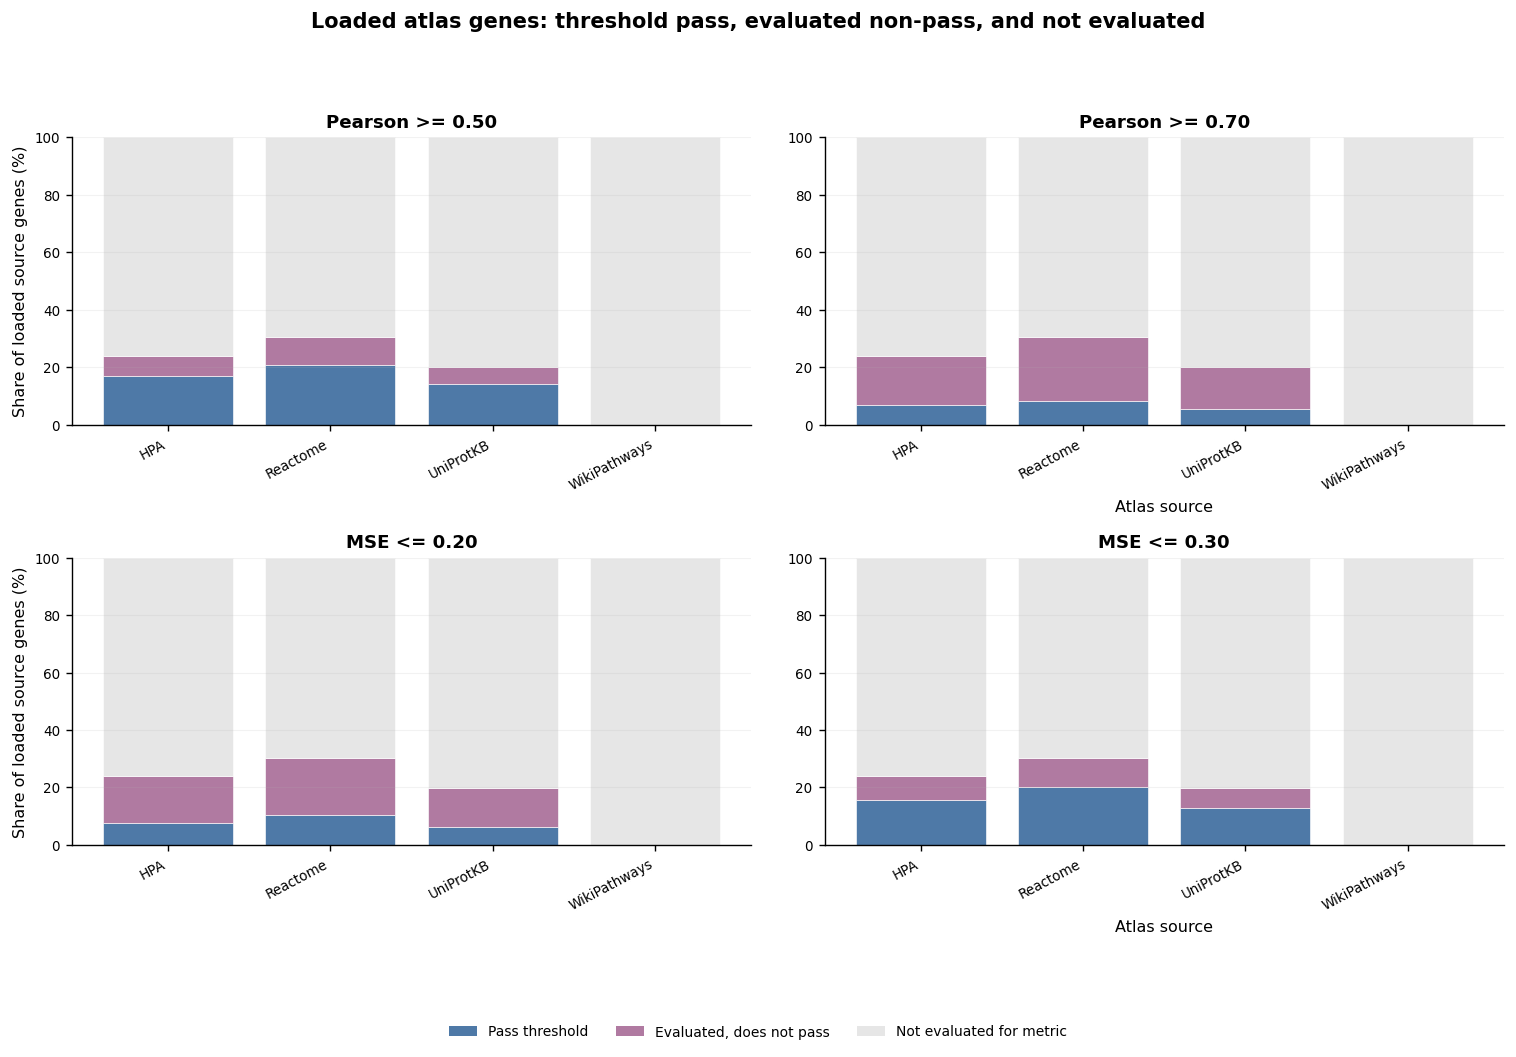

In [10]:
SOURCE_COLORS = OrderedDict([
    ('HPA', '#4E79A7'),
    ('UniProtKB', '#F28E2B'),
    ('GOA', '#59A14F'),
    ('Reactome', '#E15759'),
    ('WikiPathways', '#B07AA1'),
])
UNIVERSE_COMPONENT_COLORS = OrderedDict([
    ('Pass threshold', '#4E79A7'),
    ('Evaluated, does not pass', '#B07AA1'),
    ('Not evaluated for metric', '#E6E6E6'),
])


def source_condition_universe_decomposition():
    rows = []
    for case in condition_table.itertuples(index=False):
        metric_genes = metric_universe_sets[case.metric]
        selected_genes = set(threshold_membership.loc[threshold_membership.condition_id.eq(case.condition_id), 'gene_symbol'])
        for source, sub in atlas_unique.groupby('source', sort=True):
            loaded = set(sub.gene_symbol)
            n_loaded = len(loaded)
            n_eval = len(loaded & metric_genes)
            n_pass = len(loaded & selected_genes)
            rows.append({
                'condition_id': case.condition_id, 'condition': case.condition, 'metric': case.metric,
                'source': source, 'n_loaded': n_loaded, 'n_pass': n_pass,
                'n_evaluated_not_pass': n_eval - n_pass,
                'n_not_evaluated': n_loaded - n_eval,
                'pct_pass': 100 * n_pass / n_loaded if n_loaded else np.nan,
                'pct_evaluated_not_pass': 100 * (n_eval - n_pass) / n_loaded if n_loaded else np.nan,
                'pct_not_evaluated': 100 * (n_loaded - n_eval) / n_loaded if n_loaded else np.nan,
            })
    return pd.DataFrame(rows)


source_decomposition = source_condition_universe_decomposition()
source_decomposition.to_csv(TABLE_DIR / 'source_universe_decomposition_by_threshold.csv', index=False)


def plot_source_universe_decomposition_grid():
    fig, axes, _, _ = compact_grid(len(condition_table), panel_size=(6.1, 4.2), max_cols=2)
    for ax, case in zip(axes, condition_table.itertuples(index=False)):
        sub = source_decomposition.loc[source_decomposition.condition_id.eq(case.condition_id)].sort_values('source')
        x = np.arange(len(sub))
        bottom = np.zeros(len(sub))
        for label, col in [
            ('Pass threshold', 'pct_pass'),
            ('Evaluated, does not pass', 'pct_evaluated_not_pass'),
            ('Not evaluated for metric', 'pct_not_evaluated'),
        ]:
            values = sub[col].to_numpy(dtype=float)
            ax.bar(x, values, bottom=bottom, color=UNIVERSE_COMPONENT_COLORS[label], edgecolor='white', linewidth=0.35, label=label)
            bottom += values
        ax.set_xticks(x)
        ax.set_xticklabels(sub.source, rotation=28, ha='right')
        ax.set_ylim(0, 100)
        ax.set_ylabel('Share of loaded source genes (%)')
        ax.set_xlabel('Atlas source')
        ax.set_title(case.condition)
        ax.grid(axis='y', alpha=0.16, linewidth=0.6)
    handles = [mpl.patches.Patch(facecolor=color, label=label) for label, color in UNIVERSE_COMPONENT_COLORS.items()]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False)
    fig.suptitle('Loaded atlas genes: threshold pass, evaluated non-pass, and not evaluated', y=0.995, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.9)
    finish_figure(fig, 'main_01_source_universe_decomposition_grid')


plot_source_universe_decomposition_grid()


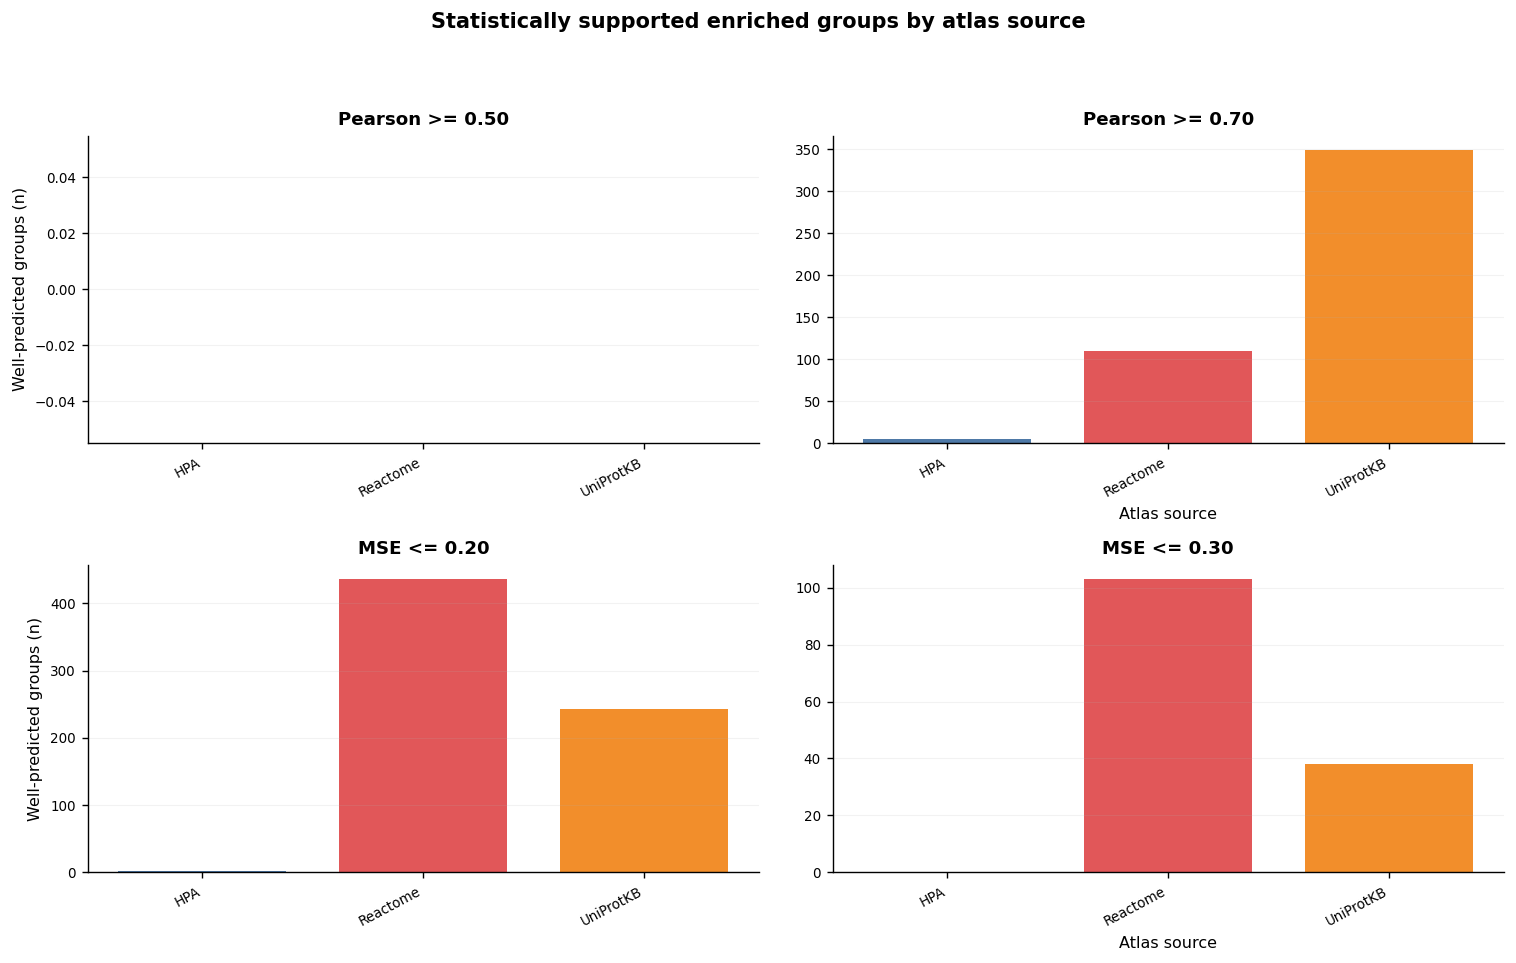

In [11]:
def plot_well_predicted_counts_grid():
    fig, axes, _, _ = compact_grid(len(condition_table), panel_size=(6.1, 4.0), max_cols=2)
    sources = sorted(atlas_group_analysis.source.unique())
    for ax, case in zip(axes, condition_table.itertuples(index=False)):
        sub = atlas_group_analysis.loc[atlas_group_analysis.condition_id.eq(case.condition_id)]
        counts = sub.loc[sub.well_predicted_group].groupby('source').group_id.nunique().reindex(sources, fill_value=0)
        x = np.arange(len(sources))
        ax.bar(x, counts.values, color=[SOURCE_COLORS.get(source, '#7F7F7F') for source in sources], width=0.76)
        ax.set_xticks(x)
        ax.set_xticklabels(sources, rotation=28, ha='right')
        ax.set_ylabel('Well-predicted groups (n)')
        ax.set_xlabel('Atlas source')
        ax.set_title(case.condition)
        ax.grid(axis='y', alpha=0.16, linewidth=0.6)
    fig.suptitle('Statistically supported enriched groups by atlas source', y=0.995, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.04, 1, 0.95), h_pad=1.2, w_pad=0.9)
    finish_figure(fig, 'main_02_well_predicted_group_counts_grid')


plot_well_predicted_counts_grid()


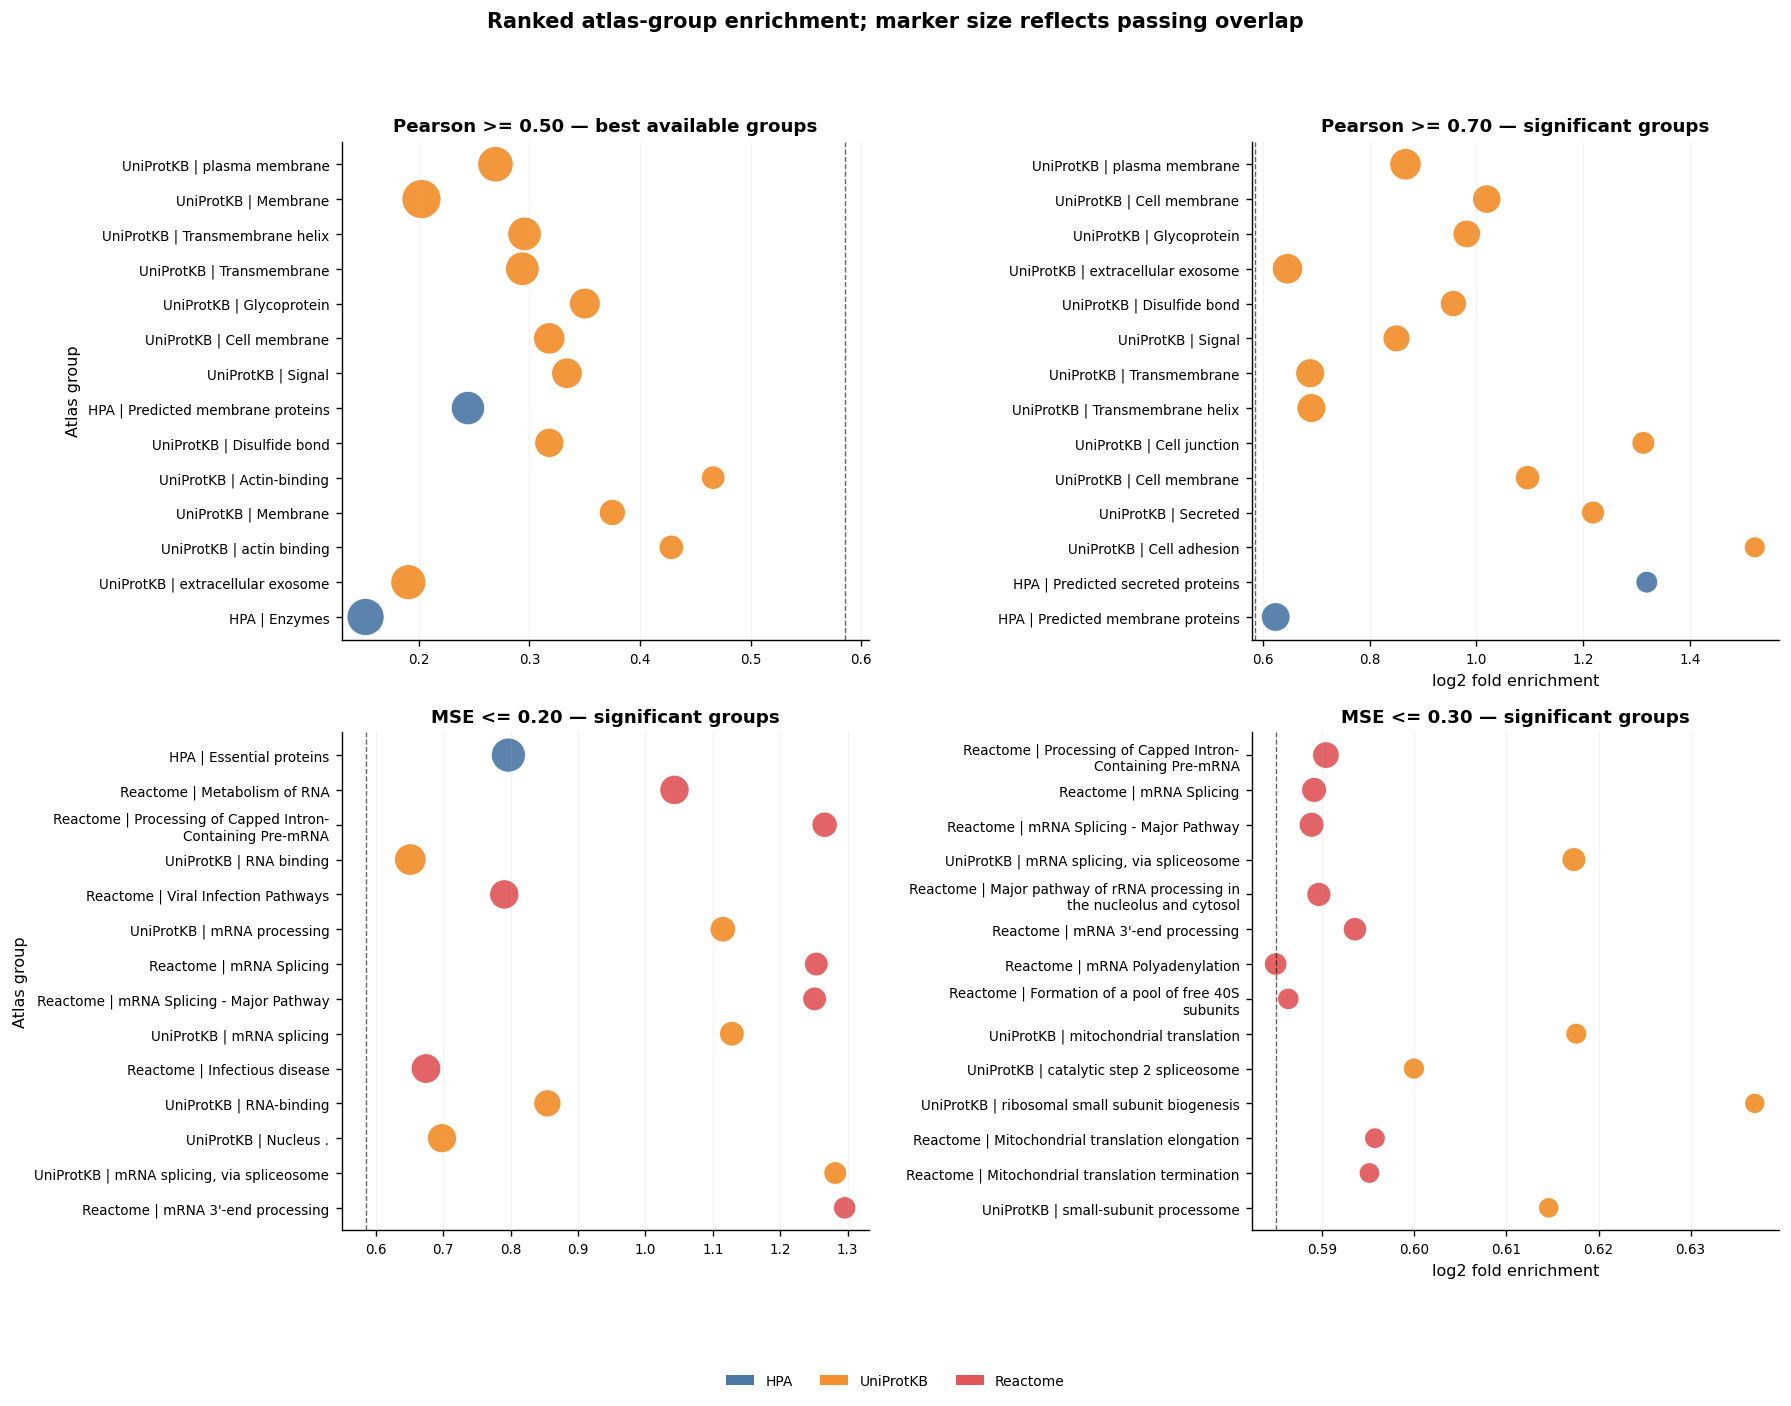

In [12]:
def ranked_groups_for_case(case_id, top_n=TOP_N_RANKED):
    sub = atlas_group_analysis.loc[
        atlas_group_analysis.condition_id.eq(case_id)
        & atlas_group_analysis.n_genes_in_metric_universe.ge(MIN_GROUP_SIZE_PLOTS)
        & atlas_group_analysis.n_genes_passing_in_group.ge(MIN_OVERLAP_FOR_FLAG)
    ].copy()
    significant = sub.loc[sub.well_predicted_group].copy()
    chosen = significant if not significant.empty else sub
    chosen = chosen.assign(
        rank_fdr=chosen.fdr_within_source_condition.fillna(1.0),
        rank_fold=chosen.fold_enrichment.fillna(0),
    )
    return chosen.sort_values(
        ['well_predicted_group', 'rank_fdr', 'rank_fold', 'n_genes_passing_in_group'],
        ascending=[False, True, False, False],
    ).head(top_n)


def plot_ranked_enrichment_grid():
    fig, axes, _, _ = compact_grid(len(condition_table), panel_size=(7.2, 5.6), max_cols=2)
    for ax, case in zip(axes, condition_table.itertuples(index=False)):
        sub = ranked_groups_for_case(case.condition_id).iloc[::-1]
        if sub.empty:
            ax.text(0.5, 0.5, 'No groups met the plotting filters', ha='center', va='center', transform=ax.transAxes)
            ax.set_axis_off()
            continue
        labels = [wrap_label(f'{r.source} | {r.group_name}', 48) for r in sub.itertuples(index=False)]
        y = np.arange(len(sub))
        x = np.log2(sub.fold_enrichment.clip(lower=1e-9))
        sizes = 34 + 13 * np.sqrt(sub.n_genes_passing_in_group.clip(lower=1))
        ax.scatter(
            x, y, s=sizes,
            c=[SOURCE_COLORS.get(source, '#7F7F7F') for source in sub.source],
            edgecolors='white', linewidth=0.55, alpha=0.92,
        )
        ax.axvline(np.log2(FOLD_ENRICHMENT_CUTOFF), color='black', linestyle='--', linewidth=0.8, alpha=0.6)
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.set_xlabel('log2 fold enrichment')
        ax.set_ylabel('Atlas group')
        ax.set_title(case.condition + (' — significant groups' if sub.well_predicted_group.any() else ' — best available groups'))
        ax.grid(axis='x', alpha=0.16, linewidth=0.6)
    handles = [mpl.patches.Patch(facecolor=color, label=source) for source, color in SOURCE_COLORS.items() if source in atlas_group_analysis.source.unique()]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=min(5, len(handles)), frameon=False)
    fig.suptitle('Ranked atlas-group enrichment; marker size reflects passing overlap', y=0.997, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.08, 1, 0.96), h_pad=1.3, w_pad=1.0)
    finish_figure(fig, 'main_03_ranked_enrichment_grid')


plot_ranked_enrichment_grid()


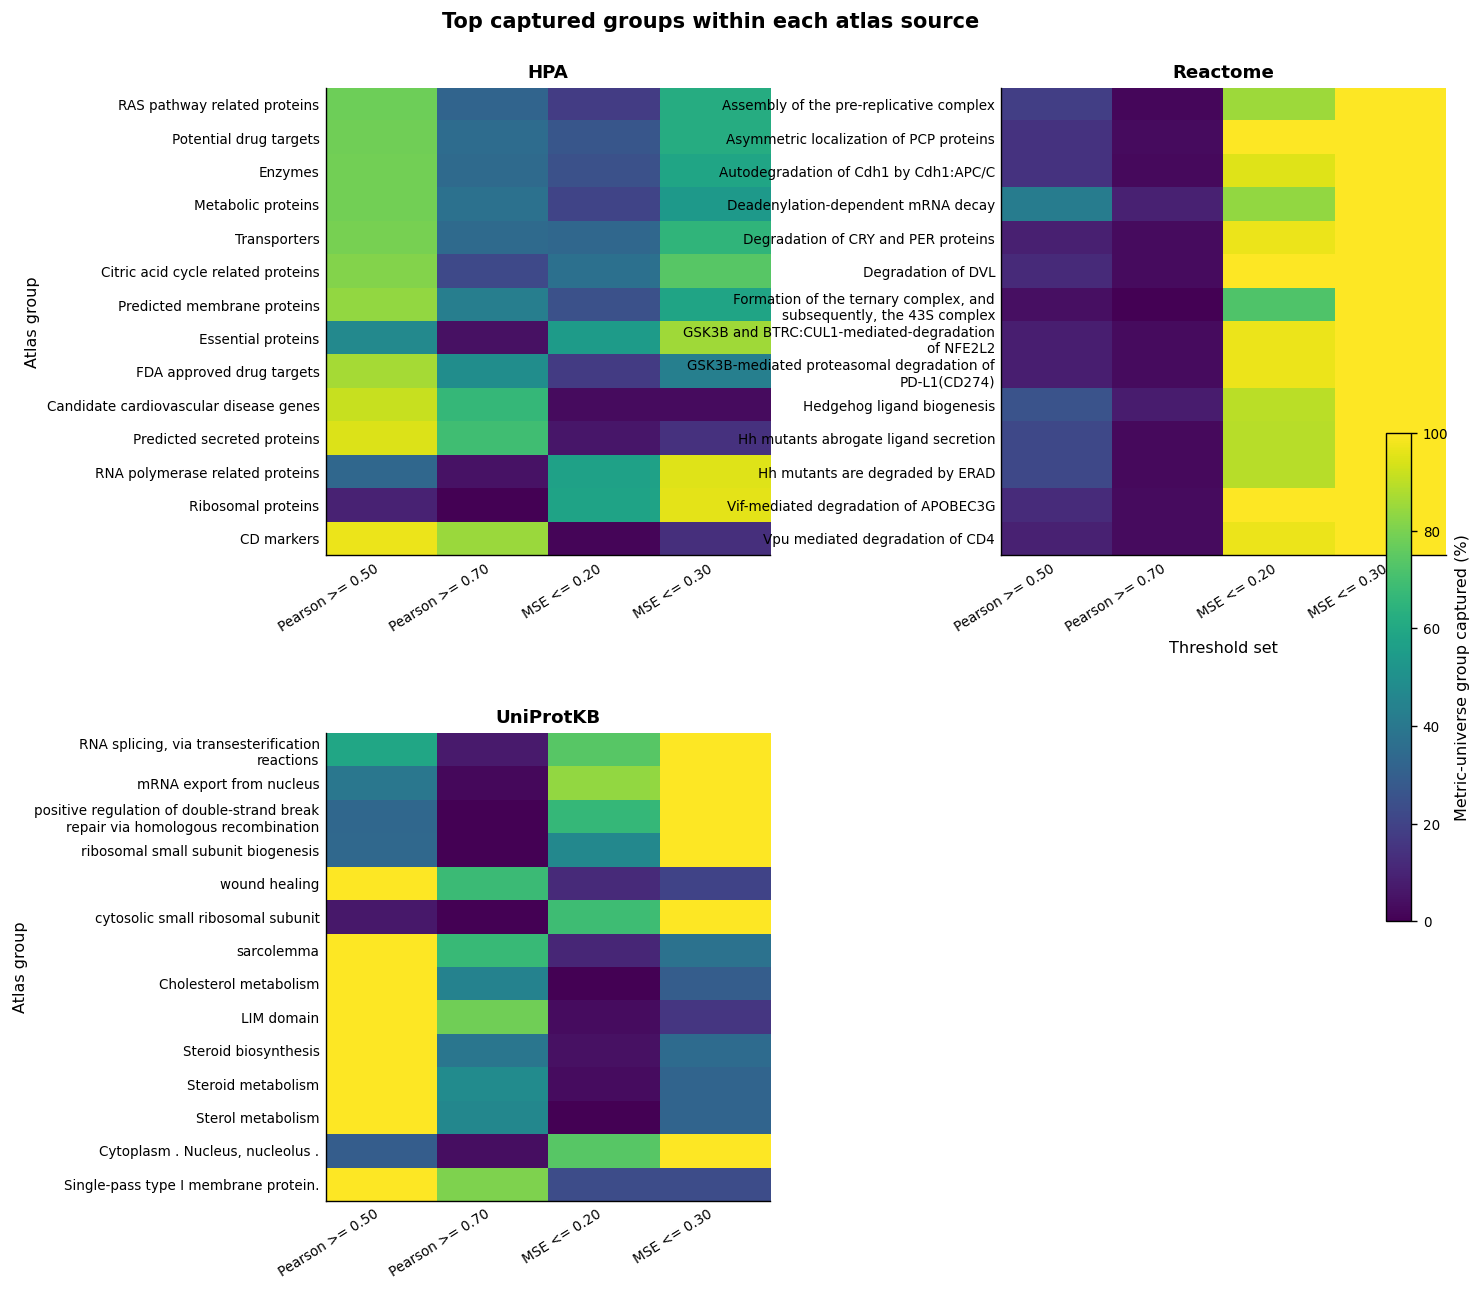

In [13]:
def plot_source_capture_heatmap_grid():
    sources = sorted(atlas_group_analysis.source.unique())
    fig, axes, _, _ = compact_grid(len(sources), panel_size=(7.0, 5.3), max_cols=2)
    image = None
    for ax, source in zip(axes, sources):
        sub = atlas_group_analysis.loc[
            atlas_group_analysis.source.eq(source)
            & atlas_group_analysis.n_genes_in_metric_universe.ge(MIN_GROUP_SIZE_PLOTS)
        ].copy()
        if sub.empty:
            ax.set_axis_off()
            continue
        ranked = (
            sub.groupby(['group_id', 'group_name'], as_index=False)
            .agg(max_capture=('pct_metric_universe_group_captured', 'max'), max_overlap=('n_genes_passing_in_group', 'max'))
            .sort_values(['max_capture', 'max_overlap'], ascending=False)
            .head(TOP_N_CAPTURE_PER_SOURCE)
        )
        matrix = (
            sub.loc[sub.group_id.isin(ranked.group_id)]
            .pivot_table(index=['group_id', 'group_name'], columns='condition', values='pct_metric_universe_group_captured', aggfunc='max', fill_value=0)
            .reindex(columns=condition_order, fill_value=0)
            .reset_index()
            .merge(ranked[['group_id', 'max_capture']], on='group_id')
            .sort_values('max_capture', ascending=True)
            .set_index(['group_id', 'group_name'])
            .drop(columns='max_capture')
        )
        image = ax.imshow(matrix.to_numpy(dtype=float), aspect='auto', vmin=0, vmax=100, interpolation='nearest', cmap='viridis')
        ax.set_xticks(np.arange(len(matrix.columns)))
        ax.set_xticklabels(matrix.columns, rotation=32, ha='right')
        ax.set_yticks(np.arange(len(matrix.index)))
        ax.set_yticklabels([wrap_label(name, 42) for _, name in matrix.index])
        ax.set_xlabel('Threshold set')
        ax.set_ylabel('Atlas group')
        ax.set_title(source)
        ax.tick_params(axis='both', length=0)
    if image is not None:
        cbar = fig.colorbar(image, ax=list(axes), fraction=0.018, pad=0.012)
        cbar.set_label('Metric-universe group captured (%)')
    fig.suptitle('Top captured groups within each atlas source', y=0.997, fontsize=12, fontweight='bold')
    fig.subplots_adjust(left=0.28, right=0.92, top=0.94, bottom=0.10, hspace=0.38, wspace=0.52)
    finish_figure(fig, 'main_04_source_capture_heatmap_grid')


plot_source_capture_heatmap_grid()


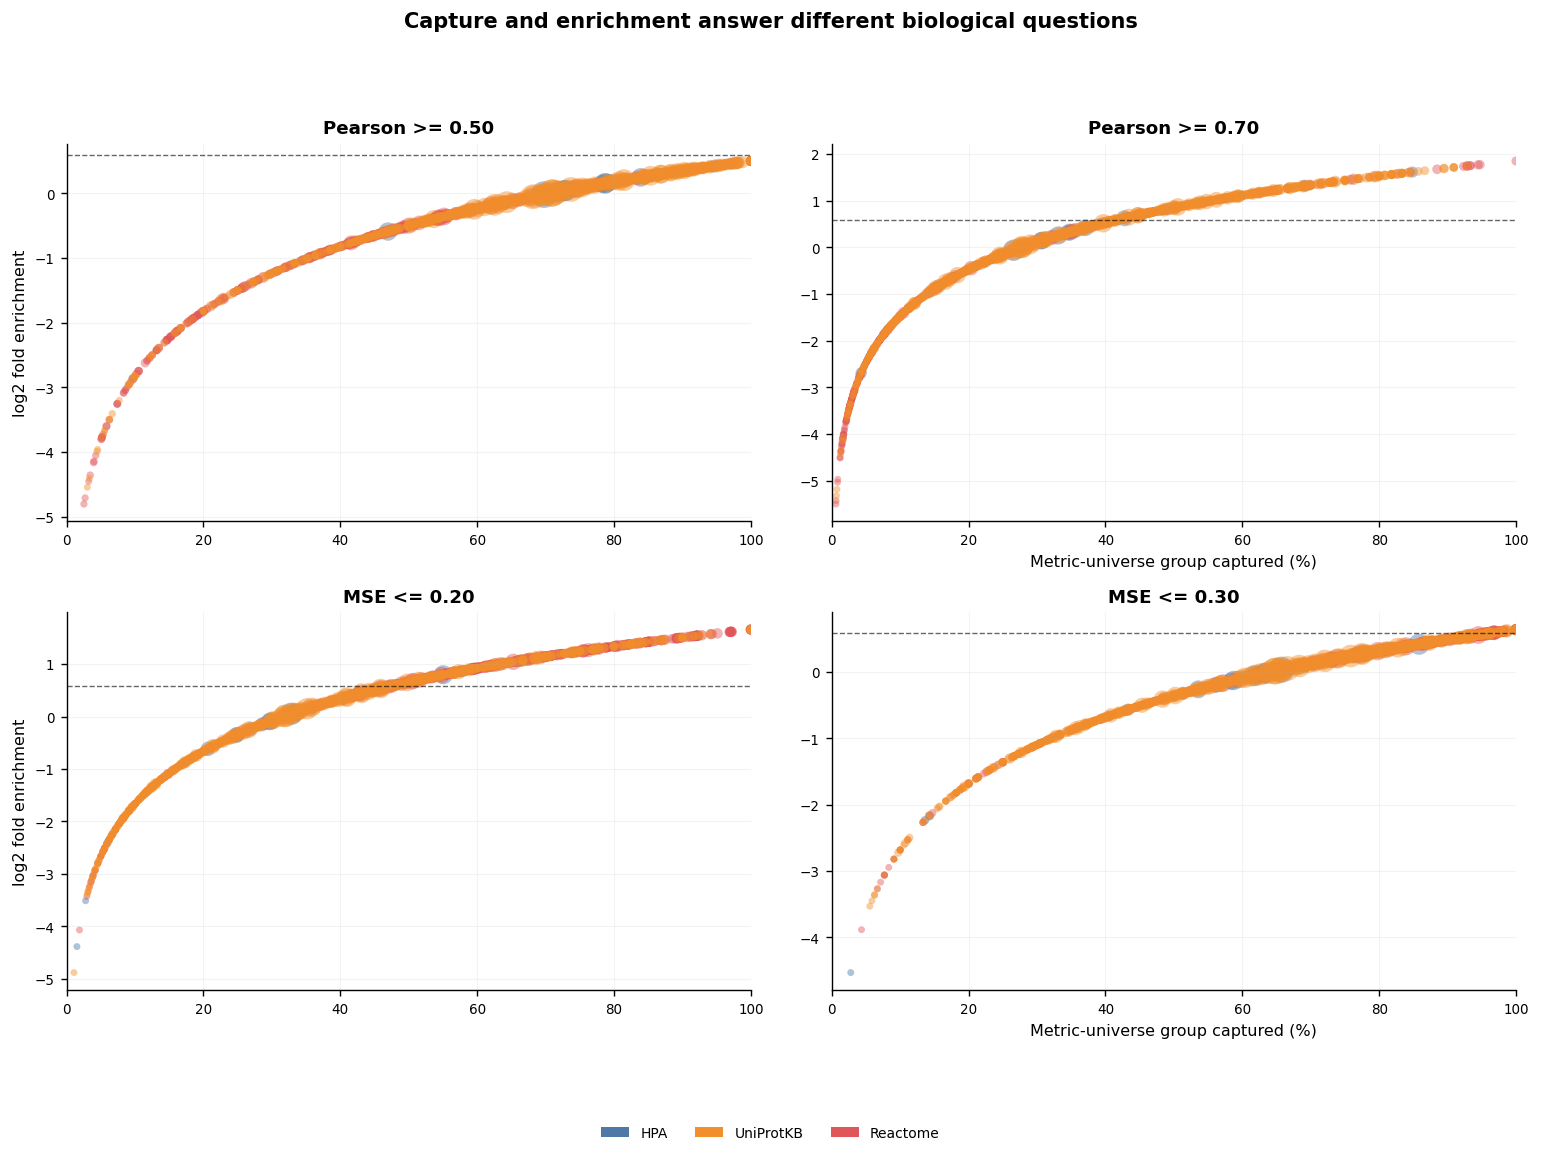

In [14]:
def plot_capture_enrichment_landscape_grid():
    fig, axes, _, _ = compact_grid(len(condition_table), panel_size=(6.2, 4.6), max_cols=2)
    for ax, case in zip(axes, condition_table.itertuples(index=False)):
        sub = atlas_group_analysis.loc[
            atlas_group_analysis.condition_id.eq(case.condition_id)
            & atlas_group_analysis.n_genes_in_metric_universe.ge(MIN_GROUP_SIZE_PLOTS)
            & atlas_group_analysis.fold_enrichment.gt(0)
        ].copy()
        for source, source_sub in sub.groupby('source'):
            ax.scatter(
                source_sub.pct_metric_universe_group_captured,
                np.log2(source_sub.fold_enrichment),
                s=12 + 4.0 * np.sqrt(source_sub.n_genes_passing_in_group.clip(lower=0)),
                c=SOURCE_COLORS.get(source, '#7F7F7F'),
                alpha=0.45, edgecolors='none', label=source,
            )
        ax.axhline(np.log2(FOLD_ENRICHMENT_CUTOFF), color='black', linestyle='--', linewidth=0.8, alpha=0.6)
        ax.set_xlim(0, 100)
        ax.set_xlabel('Metric-universe group captured (%)')
        ax.set_ylabel('log2 fold enrichment')
        ax.set_title(case.condition)
        ax.grid(alpha=0.14, linewidth=0.6)
    handles = [mpl.patches.Patch(facecolor=color, label=source) for source, color in SOURCE_COLORS.items() if source in atlas_group_analysis.source.unique()]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=min(5, len(handles)), frameon=False)
    fig.suptitle('Capture and enrichment answer different biological questions', y=0.997, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.09, 1, 0.95), h_pad=1.2, w_pad=0.9)
    finish_figure(fig, 'main_05_capture_enrichment_landscape_grid')


plot_capture_enrichment_landscape_grid()


## 8. Resource-quality and composition checks

These figures are diagnostic rather than principal biological results. They are retained because multi-atlas conclusions can be distorted by source redundancy and very different group-size distributions.


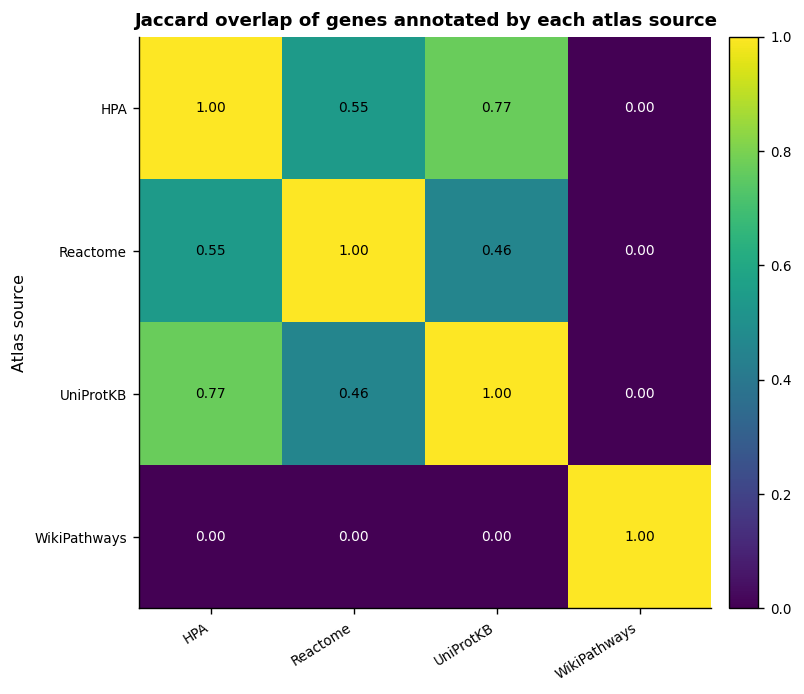

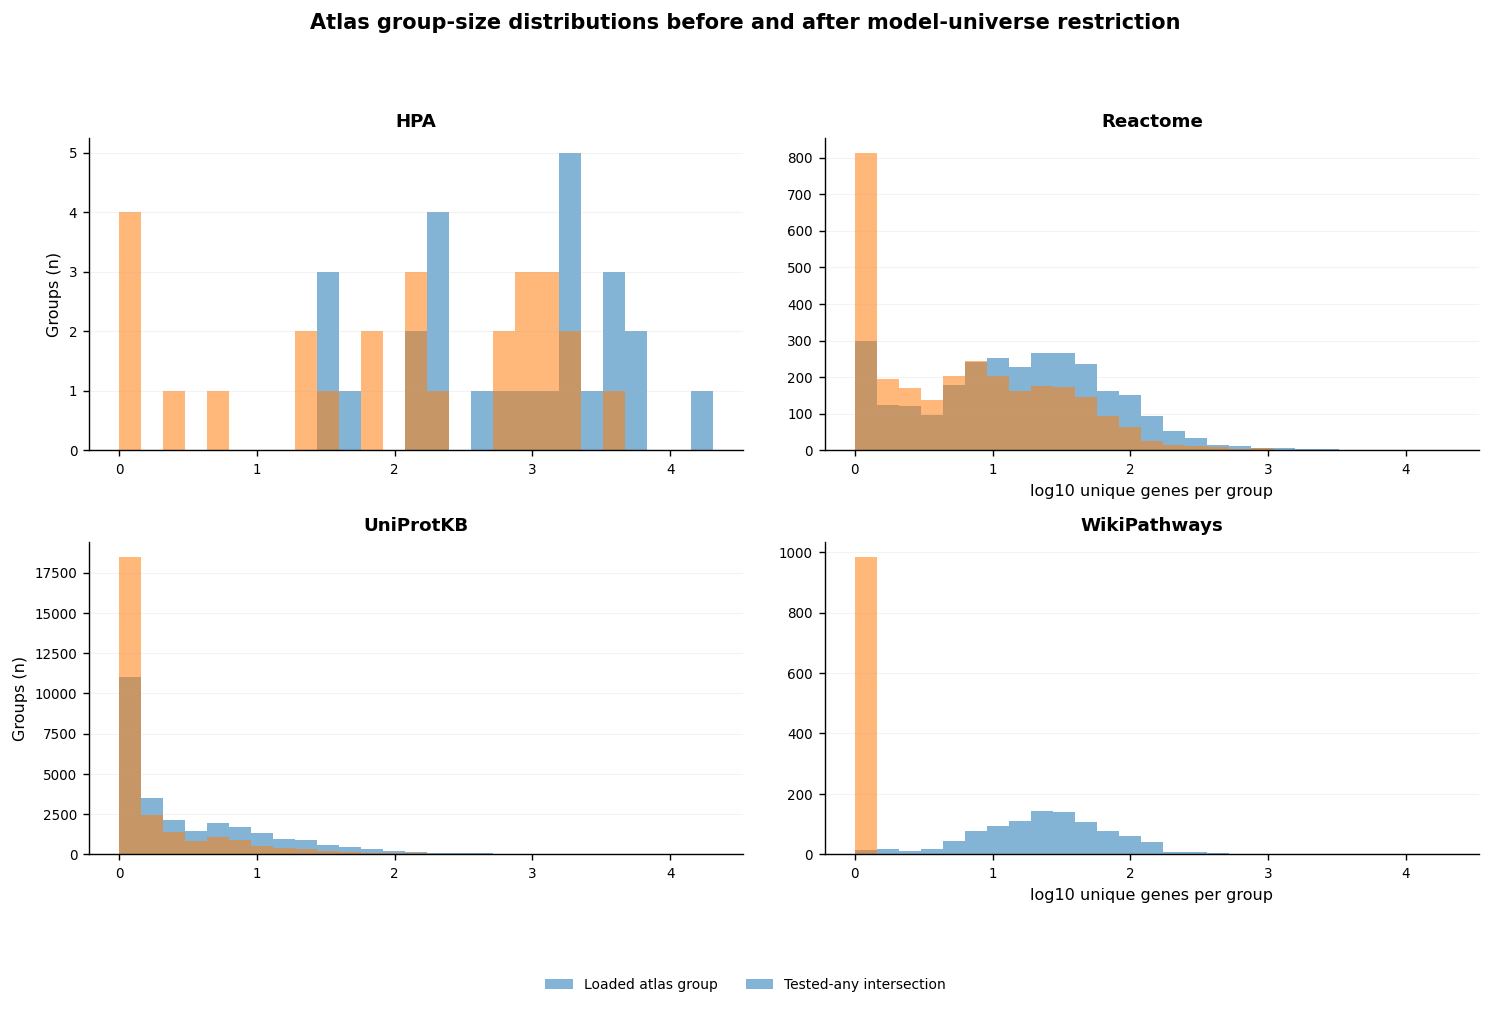

In [15]:
def plot_resource_gene_jaccard():
    sources = sorted(atlas_unique.source.unique())
    gene_sets = {source: set(atlas_unique.loc[atlas_unique.source.eq(source), 'gene_symbol']) for source in sources}
    matrix = np.zeros((len(sources), len(sources)), dtype=float)
    for i, left in enumerate(sources):
        for j, right in enumerate(sources):
            union = gene_sets[left] | gene_sets[right]
            matrix[i, j] = len(gene_sets[left] & gene_sets[right]) / len(union) if union else np.nan
    resource_jaccard = pd.DataFrame(matrix, index=sources, columns=sources)
    resource_jaccard.to_csv(TABLE_DIR / 'resource_gene_jaccard.csv')
    fig, ax = plt.subplots(figsize=(7.0, 5.8))
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(np.arange(len(sources)))
    ax.set_xticklabels(sources, rotation=32, ha='right')
    ax.set_yticks(np.arange(len(sources)))
    ax.set_yticklabels(sources)
    ax.set_xlabel('Atlas source')
    ax.set_ylabel('Atlas source')
    ax.set_title('Jaccard overlap of genes annotated by each atlas source')
    for i in range(len(sources)):
        for j in range(len(sources)):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if matrix[i, j] < 0.45 else 'black')
    cbar = fig.colorbar(image, ax=ax, fraction=0.042, pad=0.025)
    cbar.set_label('Gene-set Jaccard index')
    fig.tight_layout()
    finish_figure(fig, 'qc_01_resource_gene_jaccard', show=DISPLAY_MAIN_FIGURES)


def plot_group_size_distribution_grid():
    sources = sorted(group_reference.source.unique())
    fig, axes, _, _ = compact_grid(len(sources), panel_size=(6.0, 4.0), max_cols=2)
    bins = np.linspace(0, max(1, np.log10(group_reference.n_genes_atlas_loaded.max())), 28)
    for ax, source in zip(axes, sources):
        sub = group_reference.loc[group_reference.source.eq(source)]
        loaded = np.log10(sub.n_genes_atlas_loaded.clip(lower=1))
        tested = np.log10(sub.n_genes_tested_any_metric.clip(lower=1))
        ax.hist(loaded, bins=bins, alpha=0.55, label='Loaded atlas group')
        ax.hist(tested, bins=bins, alpha=0.55, label='Tested-any intersection')
        ax.set_xlabel('log10 unique genes per group')
        ax.set_ylabel('Groups (n)')
        ax.set_title(source)
        ax.grid(axis='y', alpha=0.14, linewidth=0.6)
    handles = [
        mpl.patches.Patch(alpha=0.55, label='Loaded atlas group'),
        mpl.patches.Patch(alpha=0.55, label='Tested-any intersection'),
    ]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=2, frameon=False)
    fig.suptitle('Atlas group-size distributions before and after model-universe restriction', y=0.997, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.09, 1, 0.95), h_pad=1.2, w_pad=0.9)
    finish_figure(fig, 'qc_02_group_size_distribution_grid', show=DISPLAY_MAIN_FIGURES)


if MAKE_QC_FIGURES:
    plot_resource_gene_jaccard()
    plot_group_size_distribution_grid()


## 9. Interpretation and output guide

### Recommended interpretation order

1. Inspect `threshold_summary.csv` and `atlas_source_universe_summary.csv` before interpreting any enrichment.
2. Use `atlas_group_universe_by_threshold.csv` to verify that a group's metric-specific denominator is sufficiently large.
3. Use `pan_atlas_group_analysis_all.csv` as the authoritative combined result table.
4. Treat `well_predicted_group` as a screening flag, not a biological truth. It requires source-specific FDR, fold enrichment and minimum overlap simultaneously.
5. Compare `pct_metric_universe_group_captured` with `pct_loaded_atlas_group_captured`. A high metric-universe capture can coexist with low loaded-atlas capture when much of the atlas group was never evaluated.
6. Use the capture–enrichment landscape to distinguish broad group recovery from statistical overrepresentation.

### Main tables

- `atlas_membership_long.csv`: normalized memberships from all parsed atlases;
- `gene_annotation_burden_by_source.csv` and `goa_evidence_summary.csv`: resource-composition audits;
- `best_pearson_mse_per_gene.csv`: independently selected best metric values and provenance;
- `threshold_membership_long.csv`: passing genes for Pearson and MSE cases;
- `atlas_group_universe_by_threshold.csv`: complete denominator audit, including zero-member groups;
- `model_genes_unmatched_to_any_atlas.csv`: identifier and coverage audit;
- `pan_atlas_group_analysis_all.csv`: capture and enrichment for every retained group-condition pair;
- `well_predicted_groups.csv`: rows passing the configured screening criteria;
- `pearson_mse_overlap_joint_universe.csv`: cross-metric overlap audit.

### Deliberately omitted repetitive figures

The merged notebook does not generate separate top-group tiles, lollipop charts, duplicate bubble matrices, 50% and 75% capture heatmaps, or multiple representations of the same ranked groups. Those views can be regenerated from the master table if a presentation requires them.


In [16]:
# Compact final audit
required_tables = [
    'atlas_membership_long.csv',
    'best_pearson_mse_per_gene.csv',
    'threshold_membership_long.csv',
    'atlas_group_universe_by_threshold.csv',
    'pan_atlas_group_analysis_all.csv',
    'well_predicted_groups.csv',
    'pearson_mse_overlap_joint_universe.csv',
]
final_audit = pd.DataFrame({
    'table': required_tables,
    'exists': [(TABLE_DIR / name).exists() for name in required_tables],
})
display(final_audit)
print('6. pan_atlas analysis complete.')
print('Tables:', TABLE_DIR.resolve())
print('Figures:', FIGURE_DIR.resolve())


,table,exists
0,atlas_membership_long.csv,True
1,best_pearson_mse_per_gene.csv,True
2,threshold_membership_long.csv,True
3,atlas_group_universe_by_threshold.csv,True
4,pan_atlas_group_analysis_all.csv,True
5,well_predicted_groups.csv,True
6,pearson_mse_overlap_joint_universe.csv,True


6. pan_atlas analysis complete.
Tables: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\6_pan_atlas_outputs\tables
Figures: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\6_pan_atlas_outputs\figures
